# PA3 Task 3 — Test-time compute: sampling, selection and adaptive inference

**Data.** The supplied ATML-PA3-Data rollouts: Qwen2.5-3B-Instruct on a 1,000-question MATH test subset and
Qwen2.5-VL-3B-Instruct on MathVista testmini, 32 rollouts per question (T = 0.7, top-p 0.8, top-k 20, 2,048-token cap),
with per-token `logp`, `kl_u_p` = D_KL(U‖p) and, for the VLM, image / prompt-text / generated-text attention totals.

**Protocol.** Per dataset the sorted question IDs are permuted with `default_rng(6304)`: first 200 = development,
remaining 800 = held-out evaluation (all numbers below are on the 800 evaluation questions unless marked *dev*).
Ten seeded permutations of the 32 rollouts per question give nested candidate prefixes for N ∈ {1, 2, 4, 8, 16, 32};
the same orders are reused by every method and stopping rule; outcomes are averaged over orders within a question and
then over questions; 95 % intervals use 1,000 paired question-level bootstrap resamples.

**Where it ran.** Kaggle (free tier): `pa3-task3-offline` (CPU) ran `offline.py` (Steps 1–3, 5) and
`pa3-task3-live` (2× T4) ran `live.py` (Step 4: Qwen2.5-3B-Instruct, pinned revision, FP16, batch 1; the 50
questions are split 25/25 across the two GPUs, every strategy of a question on the same GPU). Both jobs download the
data from the assignment's Google Drive. Everything below is computed from the files those jobs wrote (`results/`).

In [1]:
import os
os.makedirs("tt", exist_ok=True)

In [2]:
%%writefile tt/common.py
"""Shared constants, data loading, splits and rollout orders for Task 3 (test-time compute)."""
import json
import os

import numpy as np

SEED = 6304
BUDGETS = [1, 2, 4, 8, 16, 32]
N_ORDERS = 10
N_ROLL = 32
N_DEV = 200
N_LIVE = 50
NA = "NO_ANSWER"
DATASETS = {"math": "qwen25-math", "mathvista": "qwen25vl-mathvista"}
STOP_AT = [4, 8, 16]
TAUS = [0.5, 0.625, 0.75, 0.875, 1.0]
GAMMAS = [0.0, 0.1, 0.25, 0.5]


def make_split(ids):
    """Sort lexicographically, permute with default_rng(6304); first 200 = dev, rest = eval."""
    ids = sorted(ids)
    perm = list(np.random.default_rng(SEED).permutation(ids))
    return dict(order=perm, dev=perm[:N_DEV], eval=perm[N_DEV:])


def make_orders(ids):
    """Ten seeded permutations of rollout ids 0..31 per question (questions in sorted order)."""
    r = np.random.default_rng(SEED)
    return {q: np.stack([r.permutation(N_ROLL) for _ in range(N_ORDERS)]) for q in sorted(ids)}


def atomic_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, path)

Overwriting tt/common.py


In [3]:
%%writefile tt/grading.py
"""Answer normalization, answer groups and correctness (scorer v1, fixed before final evaluation).

MATH: math-verify equivalence. Distinct extracted strings of a question are clustered greedily in rollout order:
a string joins the first existing group whose representative it is equivalent to (verify(rep, s)), else starts a new
group. Groups are formed without gold answers; a group is graded by verify(gold, representative).
MathVista: the official MathVista rules (normalize_extracted_answer / safe_equal) with multiple-choice answers
represented as option letters; free-form numbers are cleaned of LaTeX wrappers before int/float conversion and
rounded to the question's precision. Missing / unparsable extractions -> one NO_ANSWER group (always incorrect).
"""
import re

from common import NA

SCORER_VERSION = "task3-scorer-v1.1"


# ----------------------------------------------------------------------------- shared
def is_missing(x):
    return x is None or (isinstance(x, float) and x != x) or str(x).strip() in ("", "None", "null")


# ----------------------------------------------------------------------------- MATH
def _mv_parse(s):
    from math_verify import parse
    try:
        return parse("\\boxed{" + s + "}")
    except Exception:
        return []


def _mv_eq(a_parsed, b_parsed):
    from math_verify import verify
    try:
        return bool(verify(a_parsed, b_parsed, timeout_seconds=5))
    except Exception:
        return False


def _plain(s):
    return re.sub(r"\s+", "", s)


def math_groups(extracted, gold):
    """extracted: list of (rollout_id, str|None) for one question -> ({rollout_id: group}, {group: correct}, reps)."""
    groups, reps, parsed, assign = [], {}, {}, {}
    gold_p = _mv_parse(gold)
    by_string = {}
    for rid, s in extracted:
        if is_missing(s):
            assign[rid] = NA
            continue
        s = s.strip()
        if s in by_string:
            assign[rid] = by_string[s]
            continue
        p = _mv_parse(s)
        g = None
        for gid in groups:
            rp = parsed[gid]
            if (p and rp and _mv_eq(rp, p)) or _plain(reps[gid]) == _plain(s):
                g = gid
                break
        if g is None:
            g = f"g{len(groups)}"
            groups.append(g); reps[g] = s; parsed[g] = p
        by_string[s] = g
        assign[rid] = g
    correct = {NA: False}
    for g in groups:
        correct[g] = bool(gold_p and parsed[g] and _mv_eq(gold_p, parsed[g])) or _plain(reps[g]) == _plain(gold)
    reps[NA] = NA
    return assign, correct, reps


# ----------------------------------------------------------------------------- MathVista
def _lev(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def _clean_num(s):
    s = str(s).strip()
    s = re.sub(r"\\text\{[^{}]*\}|\\mathrm\{[^{}]*\}", " ", s)
    s = s.replace("\\,", "").replace("\\!", "").replace("$", "").replace("\\%", "").replace("%", "")
    s = s.replace("^\\circ", "").replace("\\circ", "").replace("°", "").replace("\\left", "").replace("\\right", "")
    s = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s).strip()
    m = re.fullmatch(r"\\?d?frac\{(-?[\d.]+)\}\{(-?[\d.]+)\}", s.replace(" ", ""))
    if m:
        return float(m.group(1)) / float(m.group(2))
    try:
        return float(s)
    except ValueError:
        pass
    s = re.sub(r"(-?\d+(?:\.\d+)?)\s*\\(?:times|cdot)\s*10\^\{?(-?\d+)\}?", r"\1e\2", s)   # a \times 10^{b}
    try:
        return float(s)
    except ValueError:
        pass
    m = re.fullmatch(r"\s*(-?\d+(?:\.\d+)?(?:e-?\d+)?)\s*(?:[a-zA-Z~][a-zA-Z /^\d{}~]*)?", s)  # number + unit only
    if m:
        return float(m.group(1))
    raise ValueError(s)


def mathvista_norm(extraction, meta):
    """Official MathVista normalization; multiple choice -> option letter."""
    if is_missing(extraction):
        return NA
    e = str(extraction).strip()
    if meta["question_type"] == "multi_choice":
        choices = meta["choices"]
        letters = [chr(ord("A") + i) for i in range(len(choices))]
        m = re.findall(r"\(([a-zA-Z])\)", e)
        if m:
            e = m[0].upper()
        e2 = re.sub(r"^\\text\{(.*)\}$", r"\1", e).strip().rstrip(".")
        if e2 in letters:
            return e2
        if e2.upper() in letters and len(e2) == 1:
            return e2.upper()
        if e in choices:
            return letters[choices.index(e)]
        dist = [_lev(e, c) for c in choices]
        return letters[dist.index(min(dist))]
    at = meta["answer_type"]
    try:
        if at == "integer":
            return str(int(_clean_num(e)))
        if at == "float":
            return str(round(_clean_num(e), int(meta["precision"])))
        return e
    except (ValueError, OverflowError, TypeError):
        return NA


def mathvista_gold(meta):
    if meta["question_type"] == "multi_choice":
        return chr(ord("A") + meta["choices"].index(meta["answer"]))
    at = meta["answer_type"]
    if at == "integer":
        return str(int(float(meta["answer"])))
    if at == "float":
        return str(round(float(meta["answer"]), int(meta["precision"])))
    return str(meta["answer"]).strip()


def mathvista_groups(extracted, meta):
    gold = mathvista_gold(meta)
    assign = {rid: mathvista_norm(s, meta) for rid, s in extracted}
    correct = {g: (g != NA and g == gold) for g in set(assign.values())}
    correct[NA] = False
    return assign, correct, {g: g for g in correct}

Overwriting tt/grading.py


In [4]:
%%writefile tt/offline.py
"""Offline experiments on the supplied rollouts (Steps 1, 2, 3, 5 and the data for 6).

    python offline.py --data ATML-PA3-Data --meta testmini.json --out OUT

Writes to OUT:
  splits.json, orders_<ds>.npy                 dev/eval split and the 10 rollout orders per question
  rollouts_<ds>.parquet                        per rollout: answer group, correctness, length, L, K, V, N=32 VisConf ...
  groups_<ds>.json                             group representatives / correctness per question
  selections_<ds>.parquet                      per (question, order, N, method): selected rollout + answer, correct, cost
  adaptive_state_<ds>.parquet                  per (question, order, n): SC / RWC state used by the stopping rules
  adaptive_grid_<ds>.csv, adaptive_<ds>.json   dev grid, frozen settings, held-out per-(question, order) outcomes
  trajectories.json                            token-level signals of fixed illustrative MathVista rollouts
  scorer.json                                  scorer version, package versions, normalization coverage
"""
import argparse
import collections
import json
import multiprocessing as mp
import os
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy.stats import rankdata

import common as C
import grading as G


# ----------------------------------------------------------------------------- loading
def load(data, ds):
    d = f"{data}/{C.DATASETS[ds]}"
    gen = pq.read_table(f"{d}/generations.parquet", columns=["dataset", "sample_id", "rollout_id", "question_text",
                        "generated_token_ids", "n_generated_text_tokens", "hit_max_new_tokens", "gold_answer", "generated_text",
                        "extracted_answer"]).to_pandas()
    prob = pq.read_table(f"{d}/probability_metrics.parquet").to_pandas()
    df = gen.merge(prob, on=["dataset", "sample_id", "rollout_id"], how="inner", validate="one_to_one")
    if ds == "mathvista":
        att = pq.read_table(f"{d}/attention_metrics.parquet").to_pandas()
        df = df.merge(att, on=["dataset", "sample_id", "rollout_id"], how="inner", validate="one_to_one",
                      suffixes=("", "_att"))
    assert len(df) == 32000, len(df)
    # token-list alignment checks
    T = df["n_generated_text_tokens"].to_numpy()
    lens = {c: df[c].map(len).to_numpy() for c in ["generated_token_ids", "logp", "kl_u_p"] +
            (["img_attn_total", "prompt_text_attn_total", "generated_text_attn_total", "n_generated_text_tokens_att"]
             if ds == "mathvista" else [])}
    align = {c: bool((v == T).all()) for c, v in lens.items()}
    if ds == "mathvista":
        align["att_prefix_counts_0..T-1"] = bool(all((np.asarray(x) == np.arange(len(x))).all()
                                                     for x in df["n_generated_text_tokens_att"]))
    assert all(align.values()), align
    df = df.sort_values(["sample_id", "rollout_id"]).reset_index(drop=True)
    return df, align


# ----------------------------------------------------------------------------- grouping
def _group_math(args):
    q, ex, gold = args
    a, c, r = G.math_groups(ex, gold)
    return q, a, c, r


def add_groups(df, ds, meta):
    rows = [(q, list(zip(g.rollout_id, g.extracted_answer)), g.gold_answer.iloc[0]) for q, g in df.groupby("sample_id")]
    if ds == "math":
        with mp.Pool(max(1, os.cpu_count())) as pool:
            res = pool.map(_group_math, rows, chunksize=8)
    else:
        res = [(q, *G.mathvista_groups(ex, meta[q])) for q, ex, _ in rows]
    assign, corr, reps = {}, {}, {}
    for q, a, c, r in res:
        assign[q], corr[q], reps[q] = a, c, r
    df["group"] = [assign[q][r] for q, r in zip(df.sample_id, df.rollout_id)]
    df["correct"] = [corr[q][g] for q, g in zip(df.sample_id, df.group)]
    gold_norm = {q: G.mathvista_gold(meta[q]) for q in assign} if ds == "mathvista" else \
        dict(zip(df.sample_id, df.gold_answer))
    return df, dict(reps=reps, correct=corr, gold_norm=gold_norm)


# ----------------------------------------------------------------------------- scores
def rollout_scores(df, ds):
    T = df.n_generated_text_tokens.to_numpy().astype(float)
    mean = lambda col: np.array([np.mean(x) if len(x) else np.nan for x in col])
    df["L"] = mean(df.logp)
    df["K"] = mean(df.kl_u_p)
    if ds == "mathvista":
        vt = []
        for a, b, c in zip(df.img_attn_total, df.prompt_text_attn_total, df.generated_text_attn_total):
            a, b, c = (np.asarray(x, dtype=np.float64) for x in (a, b, c))
            vt.append(a / np.maximum(a + b + c, 1e-12))
        df["v_tok"] = vt
        df["V"] = mean(df.v_tok)
    df["T"] = T
    return df


def visconf(kl_list, v_list):
    """Candidate-set calibration (pooled 5th/95th linear percentiles of token KL over the given rollouts)."""
    pool = np.concatenate(kl_list)
    q05, q95 = np.percentile(pool, [5, 95])
    den = max(q95 - q05, 1e-8)
    Cs, Zs, Zts, cs = [], [], [], []
    for k, v in zip(kl_list, v_list):
        c = np.clip((k - q05) / den, 0.0, 1.0)
        if len(c):
            Cs.append(c.mean()); Zs.append(c.mean() * v.mean()); Zts.append((c * v).mean())
        else:
            Cs.append(np.nan); Zs.append(np.nan); Zts.append(np.nan)
        cs.append(c)
    return np.array(Cs), np.array(Zs), np.array(Zts), cs, (q05, q95)


# ----------------------------------------------------------------------------- selection rules
def sc(idx, grp):
    """Self-consistency: one vote per rollout; ties -> group with the earliest supporting rollout in this order."""
    votes, first = collections.Counter(), {}
    for p, i in enumerate(idx):
        votes[grp[i]] += 1
        first.setdefault(grp[i], p)
    win = max(votes, key=lambda g: (votes[g], -first[g]))
    return idx[first[win]], win, votes, first


def argmax_first(idx, q):
    q = np.where(np.isnan(q), -np.inf, q)
    p = int(np.argmax(q))          # first maximum = earliest rollout in the current order
    return idx[p]


def rwc(idx, grp, q):
    """Rank-weighted consensus; average ranks for ties, rank 1 = best, w = (N - r)/(N - 1)."""
    N = len(idx)
    q = np.where(np.isnan(q), -np.inf, q)
    r = rankdata(-q, method="average")
    w = (N - r) / (N - 1)
    W, first = collections.defaultdict(float), {}
    for p, i in enumerate(idx):
        W[grp[i]] += w[p]
        first.setdefault(grp[i], p)
    Wr = {g: round(v, 9) for g, v in W.items()}
    win = max(Wr, key=lambda g: (Wr[g], -first[g]))
    tot = sum(W.values())
    vals = sorted(W.values(), reverse=True)
    margin = (vals[0] - (vals[1] if len(vals) > 1 else 0.0)) / tot if tot > 0 else 0.0
    return idx[first[win]], win, margin


METHODS = {"math": ["FirstAns", "SC", "MaxLogP", "MaxSC", "SC_RWC", "Shortest"],
           "mathvista": ["FirstAns", "SC", "MaxLogP", "MaxSC", "SC_RWC", "Shortest",
                         "MaxVis", "Vis_RWC", "MaxVisConf", "VisConf_RWC", "MaxVisConfTok", "VisConfTok_RWC"]}


def run_question(q, sub, orders, ds):
    """All budgets x orders x methods for one question. sub: the 32 rollouts sorted by rollout_id."""
    grp = sub.group.tolist()
    cor = dict(zip(sub.group, sub.correct))
    T, L, K = sub["T"].to_numpy(), sub.L.to_numpy(), sub.K.to_numpy()
    if ds == "mathvista":
        V = sub.V.to_numpy()
        kl = [np.asarray(x, dtype=np.float64) for x in sub.kl_u_p]
        vt = list(sub.v_tok)
    sel, state = [], []
    for o, order in enumerate(orders):
        for N in C.BUDGETS:
            idx = list(order[:N])
            cost = float(T[idx].sum())
            cover = any(sub.correct.iloc[i] for i in idx)
            ngr = len({grp[i] for i in idx})
            out = {}
            out["FirstAns"] = (idx[0], float(T[idx[0]]))
            s_r, s_g, votes, first = sc(idx, grp)
            out["SC"] = (s_r, cost)
            if N == 1:
                for m in METHODS[ds]:
                    out[m] = (idx[0], cost)          # every rule returns the only candidate
            else:
                out["MaxLogP"] = (argmax_first(idx, L[idx]), cost)
                out["MaxSC"] = (argmax_first(idx, K[idx]), cost)
                out["SC_RWC"] = (rwc(idx, grp, K[idx])[0], cost)
                out["Shortest"] = (argmax_first(idx, -T[idx]), cost)
                if ds == "mathvista":
                    Cc, Z, Zt, _, _ = visconf([kl[i] for i in idx], [vt[i] for i in idx])
                    out["MaxVis"] = (argmax_first(idx, V[idx]), cost)
                    out["Vis_RWC"] = (rwc(idx, grp, V[idx])[0], cost)
                    out["MaxVisConf"] = (argmax_first(idx, Z), cost)
                    out["VisConf_RWC"] = (rwc(idx, grp, Z)[0], cost)
                    out["MaxVisConfTok"] = (argmax_first(idx, Zt), cost)
                    out["VisConfTok_RWC"] = (rwc(idx, grp, Zt)[0], cost)
            for m in METHODS[ds]:
                r, c = out[m]
                sel.append((q, o, N, m, int(r), grp[r], bool(cor[grp[r]]), c, cover, ngr))
            if N in C.STOP_AT + [32]:
                qual = K[idx] if ds == "math" else visconf([kl[i] for i in idx], [vt[i] for i in idx])[1]
                rr, rg, margin = rwc(idx, grp, qual) if N > 1 else (idx[0], grp[idx[0]], 1.0)
                top = max(votes.values())
                state.append((q, o, N, s_g, bool(cor[s_g]), top / N, sum(v == top for v in votes.values()) == 1,
                              s_g == C.NA, rg, margin, cost))
    return sel, state


# ----------------------------------------------------------------------------- adaptive stopping
def simulate(st, tau, gamma, quality):
    """st: adaptive_state rows of one dataset (all n). Returns per (q, o) outcome for one setting (gamma None = agreement)."""
    st = st.sort_values(["sample_id", "order", "n"])
    ok = (st.lead_frac >= tau - 1e-12) & st.lead_unique & ~st.lead_is_na
    if quality:
        ok &= (st.sc_answer == st.rwc_answer) & (st.rwc_margin >= gamma - 1e-12)
    ok |= st.n == 32
    first = st[ok].groupby(["sample_id", "order"], sort=False).head(1)
    return first[["sample_id", "order", "n", "sc_answer", "sc_correct", "cost"]].reset_index(drop=True)


def adaptive(st, split, ds):
    dev, ev = set(split["dev"]), set(split["eval"])
    sd = st[st.sample_id.isin(dev)]
    f32 = simulate(sd, 2.0, None, False)      # tau > 1 never satisfied -> always 32
    acc32 = f32.groupby("sample_id").sc_correct.mean().mean()
    grid = [("fixed32", None, None)] + [("agreement", t, None) for t in C.TAUS] + \
           [("quality", t, g) for t in C.TAUS for g in C.GAMMAS]
    rows = []
    for fam, t, g in grid:
        r = f32 if fam == "fixed32" else simulate(sd, t, g, fam == "quality")
        pq_ = r.groupby("sample_id").agg(acc=("sc_correct", "mean"), cost=("cost", "mean"), n=("n", "mean")).mean()
        rows.append(dict(family=fam, tau=t, gamma=g, dev_acc=pq_.acc, dev_cost=pq_.cost, dev_rollouts=pq_.n))
    grid_df = pd.DataFrame(rows)
    chosen = {}
    for fam in ["agreement", "quality"]:
        cand = grid_df[grid_df.family.isin([fam, "fixed32"]) & (grid_df.dev_acc >= acc32 - 0.01 - 1e-12)].copy()
        cand["t"] = cand.tau.fillna(9); cand["g"] = cand.gamma.fillna(9)
        best = cand.sort_values(["dev_cost", "dev_acc", "t", "g"], ascending=[True, False, True, True]).iloc[0]
        chosen[fam] = dict(family=best.family, tau=None if pd.isna(best.tau) else float(best.tau),
                           gamma=None if pd.isna(best.gamma) else float(best.gamma), dev_acc=float(best.dev_acc),
                           dev_cost=float(best.dev_cost))
    se = st[st.sample_id.isin(ev)]
    outs = {}
    for fam, c in chosen.items():
        if c["family"] == "fixed32":
            r = simulate(se, 2.0, None, False)
        else:
            r = simulate(se, c["tau"], c["gamma"], fam == "quality")
        outs[fam] = r
    outs["fixed32"] = simulate(se, 2.0, None, False)
    return grid_df, dict(dev_fixed32_acc=float(acc32), chosen=chosen), outs


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--meta", required=True, help="MathVista testmini.json")
    ap.add_argument("--out", required=True)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)
    meta = json.load(open(args.meta))
    splits, info = {}, {}
    import math_verify
    info["scorer_version"] = G.SCORER_VERSION
    info["math_verify_version"] = getattr(math_verify, "__version__", None)
    try:
        from importlib.metadata import version
        info["math_verify_version"] = version("math-verify")
    except Exception:
        pass
    traj = {}
    for ds in ["math", "mathvista"]:
        t0 = time.time()
        df, align = load(args.data, ds)
        ids = sorted(df.sample_id.unique())
        assert len(ids) == 1000 and (df.groupby("sample_id").size() == 32).all()
        split = C.make_split(ids)
        splits[ds] = split
        orders = C.make_orders(ids)
        np.save(f"{args.out}/orders_{ds}.npy", np.stack([orders[q] for q in ids]))
        df, groups = add_groups(df, ds, meta)
        df = rollout_scores(df, ds)
        df["split"] = df.sample_id.map(lambda q: "dev" if q in set(split["dev"]) else "eval")
        info[ds] = dict(alignment=align, rows=len(df), load_group_seconds=time.time() - t0,
                        missing_extraction=int(df.extracted_answer.map(G.is_missing).sum()),
                        no_answer_after_norm=int((df.group == C.NA).sum()), capped=int(df.hit_max_new_tokens.sum()),
                        zero_length=int((df["T"] == 0).sum()), rollout_correct_rate=float(df.correct.mean()))
        if ds == "mathvista":   # rollouts whose non-missing extraction failed numeric normalization (dev split only)
            bad = df[(df.group == C.NA) & ~df.extracted_answer.map(G.is_missing) & (df.split == "dev")]
            info[ds]["unparsable_dev_examples"] = bad.extracted_answer.head(40).tolist()
            info[ds]["unparsable_total"] = int(((df.group == C.NA) & ~df.extracted_answer.map(G.is_missing)).sum())
        print(ds, json.dumps(info[ds])[:2000], flush=True)
        json.dump(groups, open(f"{args.out}/groups_{ds}.json", "w"))
        # per-question runs
        sel, state, extra = [], [], []
        for qi, (q, sub) in enumerate(df.groupby("sample_id", sort=True)):
            sub = sub.sort_values("rollout_id")
            s, st = run_question(q, sub, orders[q], ds)
            sel += s; state += st
            if ds == "mathvista":   # N = 32 signals (order-invariant)
                kl = [np.asarray(x, dtype=np.float64) for x in sub.kl_u_p]
                Cc, Z, Zt, cs, qq = visconf(kl, list(sub.v_tok))
                corr = [float(np.corrcoef(c, v)[0, 1]) if len(c) > 2 and np.std(c) > 0 and np.std(v) > 0 else np.nan
                        for c, v in zip(cs, sub.v_tok)]
                extra += [dict(sample_id=q, rollout_id=int(r), C32=a, Z32=b, Ztok32=c, cv_corr=d)
                          for r, a, b, c, d in zip(sub.rollout_id, Cc, Z, Zt, corr)]
            if qi % 200 == 0:
                print(ds, qi, f"{time.time() - t0:.0f}s", flush=True)
        sel = pd.DataFrame(sel, columns=["sample_id", "order", "N", "method", "sel_rollout", "sel_answer", "correct",
                                         "cost", "coverage", "n_groups"])
        sel["split"] = sel.sample_id.map(lambda q: "dev" if q in set(split["dev"]) else "eval")
        sel.to_parquet(f"{args.out}/selections_{ds}.parquet", index=False)
        st = pd.DataFrame(state, columns=["sample_id", "order", "n", "sc_answer", "sc_correct", "lead_frac",
                                          "lead_unique", "lead_is_na", "rwc_answer", "rwc_margin", "cost"])
        st.to_parquet(f"{args.out}/adaptive_state_{ds}.parquet", index=False)
        keep = ["sample_id", "rollout_id", "split", "extracted_answer", "group", "correct", "gold_answer",
                "hit_max_new_tokens", "T", "L", "K"] + (["V"] if ds == "mathvista" else [])
        roll = df[keep].copy()
        if ds == "mathvista":
            roll = roll.merge(pd.DataFrame(extra), on=["sample_id", "rollout_id"])
        roll.to_parquet(f"{args.out}/rollouts_{ds}.parquet", index=False)
        # adaptive stopping
        grid, chosen, outs = adaptive(st, split, ds)
        grid.to_csv(f"{args.out}/adaptive_grid_{ds}.csv", index=False)
        for fam, r in outs.items():
            r.to_parquet(f"{args.out}/adaptive_eval_{ds}_{fam}.parquet", index=False)
        C.atomic_json(chosen, f"{args.out}/adaptive_{ds}.json")
        print(ds, "adaptive", json.dumps(chosen), flush=True)
        # question texts + generated text for qualitative examples (eval questions only, truncated)
        df[["sample_id", "rollout_id", "question_text", "generated_text"]].assign(
            generated_text=lambda x: x.generated_text.str.slice(0, 4000)).to_parquet(f"{args.out}/texts_{ds}.parquet",
                                                                                    index=False)
        if ds == "mathvista":
            # fixed rule: first 4 eval questions (split order) with mixed correctness; per question the highest-Z32
            # correct and the highest-Z32 incorrect rollout
            rz = roll.set_index(["sample_id", "rollout_id"])
            n = 0
            for q in split["eval"]:
                r = roll[roll.sample_id == q]
                if r.correct.all() or not r.correct.any():
                    continue
                sub = df[df.sample_id == q].sort_values("rollout_id")
                kl = [np.asarray(x, dtype=np.float64) for x in sub.kl_u_p]
                _, _, _, cs, qq = visconf(kl, list(sub.v_tok))
                for lab in [True, False]:
                    rid = int(r[r.correct == lab].sort_values("Z32", ascending=False).rollout_id.iloc[0])
                    row = sub[sub.rollout_id == rid].iloc[0]
                    traj[f"{q}/{rid}"] = dict(sample_id=q, rollout_id=rid, correct=lab, group=row.group,
                                              question=row.question_text[:600], text=row.generated_text[:3000],
                                              c=cs[rid].round(4).tolist(), v=np.asarray(row.v_tok).round(5).tolist(),
                                              logp=np.asarray(row.logp).round(4).tolist(), q05_q95=list(qq),
                                              Z32=float(rz.loc[(q, rid)].Z32), cv_corr=float(rz.loc[(q, rid)].cv_corr))
                n += 1
                if n == 4:
                    break
        info[ds]["seconds"] = time.time() - t0
    C.atomic_json(splits, f"{args.out}/splits.json")
    C.atomic_json(info, f"{args.out}/scorer.json")
    C.atomic_json(traj, f"{args.out}/trajectories.json")
    print("offline done", flush=True)


if __name__ == "__main__":
    main()

Overwriting tt/offline.py


In [5]:
%%writefile tt/live.py
"""Step 4: single long response vs 3 parallel samples vs sequential refinement on 50 MATH eval questions.

    python live.py --data ATML-PA3-Data --out OUT --shard 0 --n_shards 2

Each shard (one GPU) handles a contiguous block of the 50 questions; all strategies of a question run on the same GPU.
Writes OUT/live_calls_<shard>.jsonl (one row per generation call, resumable) and OUT/live_env_<shard>.json.
"""
import argparse
import hashlib
import json
import os
import time

import pyarrow.parquet as pq
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

import common as C

MODEL = "Qwen/Qwen2.5-3B-Instruct"
REVISION = "aa8e72537993ba99e69dfaafa59ed015b17504d1"
SYSTEM = "You are a helpful assistant."
SUFFIX = "Think step by step inside <think> </think> tags, then give your final answer inside \\boxed{}."
REVIEW = ("Review the solution above. Identify and correct any errors; if it is correct, retain its answer. "
          "Give your final answer inside \\boxed{}.")
SAMPLING = dict(do_sample=True, temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.0)
CAPS = dict(single=3072, parallel=1024, refine=2048)


def last_boxed(text):
    """Last literal \\boxed{ with balanced braces; absent, empty or unclosed -> None (README rule)."""
    i = text.rfind("\\boxed{")
    if i < 0:
        return None
    j, depth = i + len("\\boxed{"), 1
    start = j
    while j < len(text):
        if text[j] == "{":
            depth += 1
        elif text[j] == "}":
            depth -= 1
            if depth == 0:
                s = text[start:j].strip()
                return s or None
        j += 1
    return None


def seed_for(qid, strategy, k):
    return int(hashlib.sha256(f"{C.SEED}|{qid}|{strategy}|{k}".encode()).hexdigest()[:8], 16)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--shard", type=int, default=0)
    ap.add_argument("--n_shards", type=int, default=1)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)
    g = pq.read_table(f"{args.data}/qwen25-math/generations.parquet",
                      columns=["sample_id", "rollout_id", "question_text", "gold_answer"]).to_pandas()
    g = g[g.rollout_id == 0].set_index("sample_id")
    split = C.make_split(list(g.index))
    live = split["eval"][:C.N_LIVE]
    per = -(-len(live) // args.n_shards)
    mine = live[args.shard * per:(args.shard + 1) * per]
    path = f"{args.out}/live_calls_{args.shard}.jsonl"
    done = set()
    if os.path.exists(path):
        done = {(r["sample_id"], r["strategy"], r["k"]) for r in map(json.loads, open(path))}
    tok = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
    model = AutoModelForCausalLM.from_pretrained(MODEL, revision=REVISION, dtype=torch.float16).cuda().eval()
    eos = set(model.generation_config.eos_token_id if isinstance(model.generation_config.eos_token_id, list)
              else [model.generation_config.eos_token_id])
    env = dict(model=MODEL, revision=REVISION, dtype="float16", batch_size=1, gpu=torch.cuda.get_device_name(0),
               torch=torch.__version__, transformers=__import__("transformers").__version__, eos_ids=sorted(eos),
               sampling=SAMPLING, caps=CAPS, questions=mine)
    json.dump(env, open(f"{args.out}/live_env_{args.shard}.json", "w"), indent=1)

    def gen(messages, cap, seed):
        prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        ids = tok(prompt, return_tensors="pt").input_ids.cuda()
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        with torch.no_grad():
            out = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=cap,
                                 pad_token_id=tok.pad_token_id, **SAMPLING)
        new = out[0, ids.shape[1]:].tolist()
        stopped = len(new) > 0 and new[-1] in eos
        kept = new[:-1] if stopped else new
        text = tok.decode(kept, skip_special_tokens=True)
        torch.cuda.synchronize()
        dt = time.time() - t0
        return dict(prompt=prompt, input_tokens=int(ids.shape[1]), output_tokens=len(new), retained_tokens=len(kept),
                    truncated=bool(not stopped and len(new) >= cap), cap=cap, seed=seed, seconds=dt,
                    peak_mem_gb=torch.cuda.max_memory_allocated() / 2**30, response=text,
                    extracted=last_boxed(text))

    gen([{"role": "user", "content": "1+1?"}], 8, 0)   # warm-up, not recorded
    f = open(path, "a")
    for qid in mine:
        prob, gold = g.loc[qid, "question_text"], g.loc[qid, "gold_answer"]
        base = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prob + "\n\n" + SUFFIX}]
        calls = [("single", 0, base, CAPS["single"])] + [("parallel", k, base, CAPS["parallel"]) for k in range(3)]
        for strategy, k, msgs, cap in calls:
            if (qid, strategy, k) in done:
                continue
            r = gen(msgs, cap, seed_for(qid, strategy, k))
            f.write(json.dumps(dict(sample_id=qid, strategy=strategy, k=k, gold=gold, **r)) + "\n"); f.flush()
        if (qid, "refine", 0) not in done:
            first = [json.loads(l) for l in open(path)]
            first = next(r for r in first if r["sample_id"] == qid and r["strategy"] == "parallel" and r["k"] == 0)
            msgs = base + [{"role": "assistant", "content": first["response"]}, {"role": "user", "content": REVIEW}]
            r = gen(msgs, CAPS["refine"], seed_for(qid, "refine", 0))
            f.write(json.dumps(dict(sample_id=qid, strategy="refine", k=0, gold=gold, **r)) + "\n"); f.flush()
        print("done", qid, flush=True)
    print("live done", flush=True)


def grade(out):
    """Correctness and per-strategy accounting (gold answers used only here, after all generation)."""
    import glob
    import grading as G
    rows = [json.loads(l) for p in sorted(glob.glob(f"{out}/live_calls_*.jsonl")) for l in open(p)]
    by = {}
    for r in rows:
        by.setdefault(r["sample_id"], {})[(r["strategy"], r["k"])] = r
    res = []
    for qid, d in by.items():
        gold = d[("single", 0)]["gold"]
        cor = lambda s: G.math_groups([(0, s)], gold)[1][G.math_groups([(0, s)], gold)[0][0]]
        par = [d[("parallel", k)] for k in range(3)]
        a, c, reps = G.math_groups([(k, p["extracted"]) for k, p in enumerate(par)], gold)
        votes = {}
        for k in range(3):
            votes.setdefault(a[k], []).append(k)
        win = max(votes, key=lambda x: (len(votes[x]), -votes[x][0]))
        ref = d[("refine", 0)]
        res.append(dict(sample_id=qid, gold=gold,
                        single_answer=d[("single", 0)]["extracted"], single_correct=bool(cor(d[("single", 0)]["extracted"])),
                        parallel_answers=[p["extracted"] for p in par], parallel_groups=[a[k] for k in range(3)],
                        parallel_answer=reps[win], parallel_correct=bool(c[win]),
                        parallel_coverage=bool(any(c[a[k]] for k in range(3))),
                        initial_answer=par[0]["extracted"], initial_correct=bool(c[a[0]]),
                        refine_answer=ref["extracted"], refine_correct=bool(cor(ref["extracted"]))))
    json.dump(res, open(f"{out}/live_graded.json", "w"), indent=1)
    print("graded", len(res), flush=True)


if __name__ == "__main__":
    import sys
    if "--grade" in sys.argv:
        grade(sys.argv[sys.argv.index("--grade") + 1])
    else:
        main()

Overwriting tt/live.py


## How the jobs were launched

```bash
pip install gdown 'math-verify[antlr4_13_2]' pyarrow
gdown --folder <ATML-PA3-Data drive link>                     # data
curl -o testmini.json https://raw.githubusercontent.com/lupantech/MathVista/main/data/testmini.json
python offline.py --data ATML-PA3-Data --meta testmini.json --out OUT                     # CPU job
CUDA_VISIBLE_DEVICES=0 python live.py --data ATML-PA3-Data --out OUT --shard 0 --n_shards 2 &  # GPU job
CUDA_VISIBLE_DEVICES=1 python live.py --data ATML-PA3-Data --out OUT --shard 1 --n_shards 2
python live.py --grade OUT
```

In [6]:
import json, glob, collections, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
R = "results"
DS = ["math", "mathvista"]
NAME = {"math": "MATH (Qwen2.5-3B)", "mathvista": "MathVista (Qwen2.5-VL-3B)"}
splits = json.load(open(f"{R}/splits.json")); scorer = json.load(open(f"{R}/scorer.json"))
sel = {d: pd.read_parquet(f"{R}/selections_{d}.parquet") for d in DS}
roll = {d: pd.read_parquet(f"{R}/rollouts_{d}.parquet") for d in DS}
BUD = [1, 2, 4, 8, 16, 32]
rng = np.random.default_rng(6304)
BOOT = {d: rng.integers(0, len(splits[d]["eval"]), size=(1000, len(splits[d]["eval"]))) for d in DS}

def per_q(df, col):
    # average over orders within each question (eval split), indexed in split order
    return df.groupby("sample_id")[col].mean()

def acc_curve(d, method, col="correct", split="eval"):
    s = sel[d][(sel[d].method == method) & (sel[d].split == split)]
    return s.groupby(["N", "sample_id"])[col].mean().groupby("N").mean()

def boot_diff(d, a, b, N, col="correct"):
    s = sel[d][(sel[d].split == "eval") & (sel[d].N == N)]
    ids = splits[d]["eval"]
    x = s[s.method == a].groupby("sample_id")[col].mean().reindex(ids).to_numpy()
    y = s[s.method == b].groupby("sample_id")[col].mean().reindex(ids).to_numpy()
    diff = x - y; bs = diff[BOOT[d]].mean(1)
    return diff.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

## 0. Data checks, answer normalization and splits

In [7]:
print("scorer:", scorer["scorer_version"], "| math-verify", scorer["math_verify_version"])
rows = []
for d in DS:
    i = scorer[d]
    rows.append(dict(dataset=NAME[d], rows=i["rows"], token_lists_aligned=all(i["alignment"].values()),
                     missing_extraction=i["missing_extraction"], NO_ANSWER_after_normalization=i["no_answer_after_norm"],
                     capped=i["capped"], rollout_accuracy=round(i["rollout_correct_rate"], 4)))
display(pd.DataFrame(rows).set_index("dataset"))
print("alignment checks:", {d: scorer[d]["alignment"] for d in DS})
print("MathVista non-missing extractions that fail normalization (-> NO_ANSWER):", scorer["mathvista"]["unparsable_total"])
print("examples (dev split):", scorer["mathvista"]["unparsable_dev_examples"][:15])
for d in DS:
    print(d, "dev ids:", splits[d]["dev"][:5], "... eval ids:", splits[d]["eval"][:5], "...  live (first 50 eval):",
          splits[d]["eval"][:5] if d == "math" else "-")

scorer: task3-scorer-v1.1 | math-verify 0.9.0


,rows,token_lists_aligned,missing_extraction,NO_ANSWER_after_normalization,capped,rollout_accuracy
dataset,,,,,,
MATH (Qwen2.5-3B),32000,True,521,521,523,0.6632
MathVista (Qwen2.5-VL-3B),32000,True,3032,4129,487,0.5441


alignment checks: {'math': {'generated_token_ids': True, 'logp': True, 'kl_u_p': True}, 'mathvista': {'generated_token_ids': True, 'logp': True, 'kl_u_p': True, 'img_attn_total': True, 'prompt_text_attn_total': True, 'generated_text_attn_total': True, 'n_generated_text_tokens_att': True, 'att_prefix_counts_0..T-1': True}}
MathVista non-missing extractions that fail normalization (-> NO_ANSWER): 1097
examples (dev split): ['15-20 years', '10-20 years', '10-15 years', '40-50', '20-30', '20-30', '1-2', '10-15 years', '5-10', '10-15 years', '0-5 years', '5-10 years', '10-20', '10-15 years', '10-15 years']
math dev ids: ['test:4388', 'test:1139', 'test:3909', 'test:2897', 'test:3752'] ... eval ids: ['test:943', 'test:2688', 'test:3504', 'test:4335', 'test:2460'] ...  live (first 50 eval): ['test:943', 'test:2688', 'test:3504', 'test:4335', 'test:2460']
mathvista dev ids: ['782', '119', '680', '469', '65'] ... eval ids: ['99', '425', '601', '77', '379'] ...  live (first 50 eval): -


Normalization (scorer v1.1, fixed before final evaluation): **MATH** — math-verify 0.9.0 equivalence; distinct
extracted strings of a question are clustered greedily in rollout order against each group's first member, without
gold answers; groups are graded with `verify(gold, representative)`. **MathVista** — the official
`normalize_extracted_answer` rules: multiple-choice answers become option letters (explicit letter / `(X)`, exact
choice text, else most similar choice by edit distance), integers via `int(float(x))`, floats rounded to the
question's `precision`, after stripping LaTeX wrappers / units and reading `a \times 10^{b}`. Missing or unparsable
extractions form one NO_ANSWER group that stays in voting, cost and accuracy and is always graded incorrect.
The only scorer change (v1 → v1.1, scientific notation and unit strings) was made from development-split examples.

## 1. The opportunity from repeated sampling

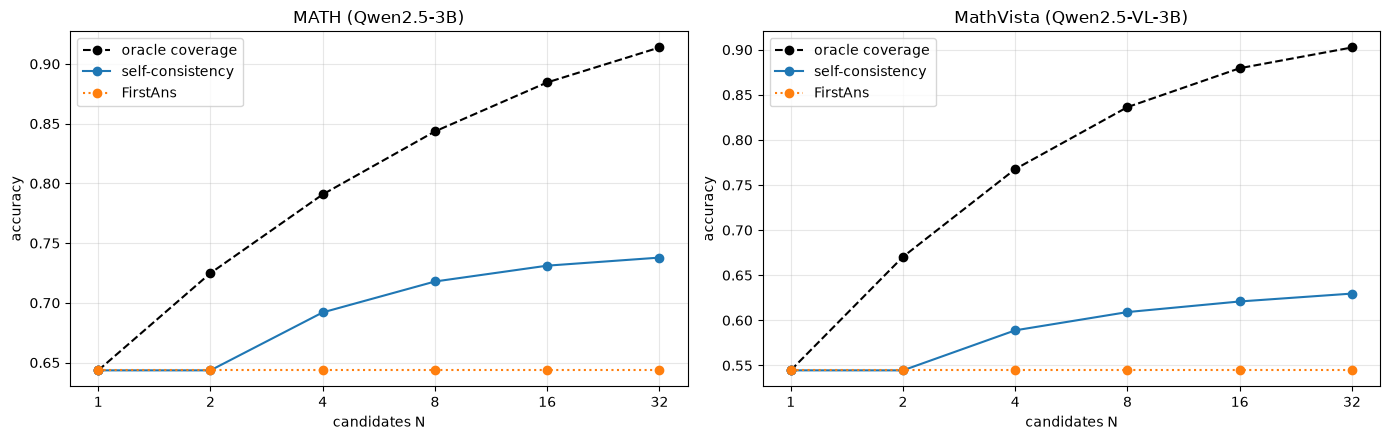

**MATH (Qwen2.5-3B)** (eval, mean over orders)

,FirstAns,oracle coverage,SC,distinct answer groups
N,,,,
1,0.6435,0.6435,0.6435,1.0000
2,0.6435,0.7249,0.6435,1.3709
4,0.6435,0.7908,0.6920,1.9278
8,0.6435,0.8435,0.7179,2.7407
16,0.6435,0.8845,0.7311,4.0042
32,0.6435,0.9138,0.7379,5.9050


**MathVista (Qwen2.5-VL-3B)** (eval, mean over orders)

,FirstAns,oracle coverage,SC,distinct answer groups
N,,,,
1,0.5445,0.5445,0.5445,1.0000
2,0.5445,0.6704,0.5445,1.4259
4,0.5445,0.7676,0.5889,1.9436
8,0.5445,0.8364,0.6091,2.5631
16,0.5445,0.8795,0.6209,3.2884
32,0.5445,0.9025,0.6296,4.1363


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tab = {}
for a, d in zip(ax, DS):
    fa = acc_curve(d, "FirstAns"); cov = acc_curve(d, "SC", "coverage"); sc = acc_curve(d, "SC")
    ng = acc_curve(d, "SC", "n_groups")
    a.plot(BUD, cov, "k--o", label="oracle coverage"); a.plot(BUD, sc, "o-", label="self-consistency")
    a.plot(BUD, fa, "o:", label="FirstAns")
    a.set_xscale("log", base=2); a.set_xticks(BUD, BUD); a.set_title(NAME[d]); a.set_xlabel("candidates N"); a.set_ylabel("accuracy")
    a.legend(); a.grid(alpha=.3)
    tab[d] = pd.DataFrame({"FirstAns": fa, "oracle coverage": cov, "SC": sc, "distinct answer groups": ng})
plt.tight_layout(); plt.show()
for d in DS:
    display(Markdown(f"**{NAME[d]}** (eval, mean over orders)")); display(tab[d].round(4))

In [9]:
# decomposition of selection failures: no correct candidate (sampling) vs correct candidate available but missed (selection)
rows = []
for d in DS:
    for m in ["SC", "SC_RWC"] + (["VisConf_RWC"] if d == "mathvista" else []):
        s = sel[d][(sel[d].method == m) & (sel[d].split == "eval")]
        for N, g in s.groupby("N"):
            q = g.groupby("sample_id").agg(c=("correct", "mean"), cov=("coverage", "mean"))
            no_cand = (1 - q["cov"]).mean(); missed = (q["cov"] - q["c"]).mean()
            rows.append(dict(dataset=d, method=m, N=N, accuracy=q.c.mean(), no_correct_candidate=no_cand,
                             correct_available_missed=missed, missed_share_of_errors=missed / max(1e-9, no_cand + missed)))
dec = pd.DataFrame(rows).set_index(["dataset", "method", "N"]).round(4)
display(dec)

accuracy  no_correct_candidate  correct_available_missed  missed_share_of_errors
dataset   method      N                                                                                   
math      SC          1     0.6435                0.3565                    0.0000                  0.0000
                      2     0.6435                0.2751                    0.0814                  0.2283
                      4     0.6920                0.2093                    0.0988                  0.3206
                      8     0.7179                0.1565                    0.1256                  0.4453
                      16    0.7311                0.1155                    0.1534                  0.5704
                      32    0.7379                0.0862                    0.1759                  0.6710
          SC_RWC      1     0.6435                0.3565                    0.0000                  0.0000
                      2     0.6676                0.2751                    0.0572                  0.1722
                      4     0.6970                0.2093                    0.0938                  0.3094
                      8     0.7286                0.1565                    0.1149                  0.4233
                      16    0.7465                0.1155                    0.1380                  0.5444
                      32    0.7555                0.0862                    0.1582                  0.6472
mathvista SC          1     0.5445                0.4555                    0.0000                  0.0000
                      2     0.5445                0.3296                    0.1259                  0.2763
                      4     0.5889                0.2324                    0.1788                  0.4348
                      8     0.6091                0.1636                    0.2272                  0.5814
                      16    0.6209                0.1205                    0.2586                  0.6822
                      32    0.6296                0.0975                    0.2729                  0.7368
          SC_RWC      1     0.5445                0.4555                    0.0000                  0.0000
                      2     0.5570                0.3296                    0.1134                  0.2559
                      4     0.5790                0.2324                    0.1886                  0.4480
                      8     0.6119                0.1636                    0.2245                  0.5784
                      16    0.6250                0.1205                    0.2545                  0.6787
                      32    0.6400                0.0975                    0.2625                  0.7292
          VisConf_RWC 1     0.5445                0.4555                    0.0000                  0.0000
                      2     0.5621                0.3296                    0.1082                  0.2472
                      4     0.5878                0.2324                    0.1799                  0.4363
                      8     0.6181                0.1636                    0.2182                  0.5715
                      16    0.6297                0.1205                    0.2498                  0.6745
                      32    0.6425                0.0975                    0.2600                  0.7273

## 2. Quality scores and aggregation: method comparison

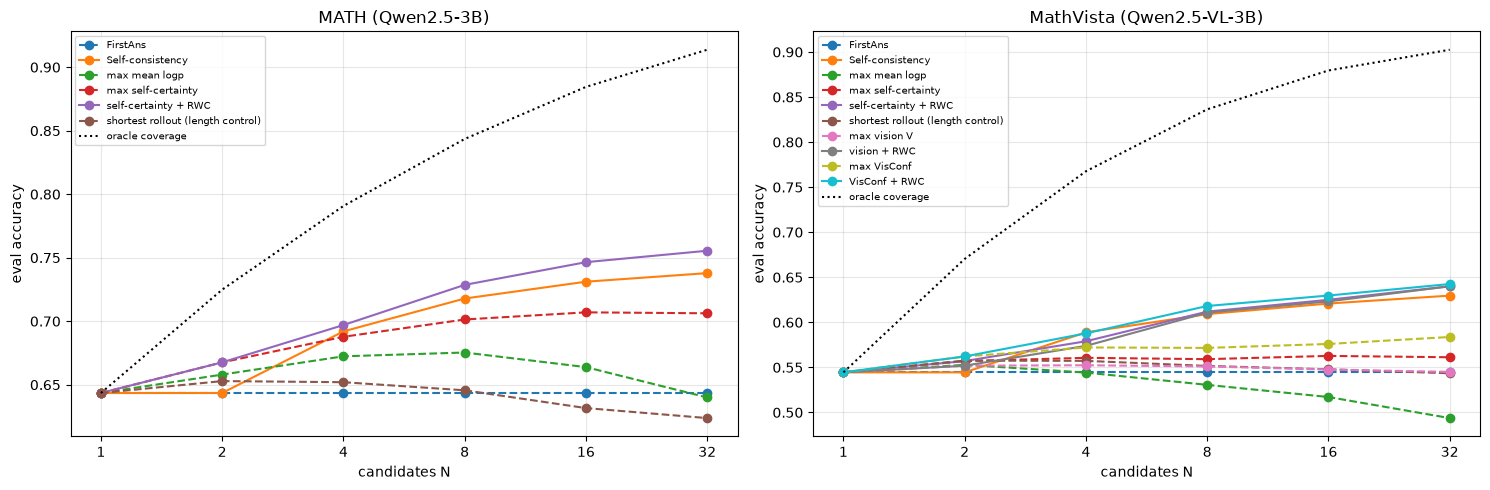

**MATH (Qwen2.5-3B): eval accuracy by method and budget**

,N=1,N=2,N=4,N=8,N=16,N=32
FirstAns,0.6435,0.6435,0.6435,0.6435,0.6435,0.6435
Self-consistency,0.6435,0.6435,0.6920,0.7179,0.7311,0.7379
max mean logp,0.6435,0.6580,0.6724,0.6754,0.6639,0.6400
max self-certainty,0.6435,0.6676,0.6878,0.7014,0.7070,0.7062
self-certainty + RWC,0.6435,0.6676,0.6970,0.7286,0.7465,0.7555
shortest rollout (length control),0.6435,0.6529,0.6520,0.6456,0.6316,0.6238


**MathVista (Qwen2.5-VL-3B): eval accuracy by method and budget**

,N=1,N=2,N=4,N=8,N=16,N=32
FirstAns,0.5445,0.5445,0.5445,0.5445,0.5445,0.5445
Self-consistency,0.5445,0.5445,0.5889,0.6091,0.6209,0.6296
max mean logp,0.5445,0.5529,0.5442,0.5306,0.5171,0.4938
max self-certainty,0.5445,0.5570,0.5606,0.5591,0.5628,0.5612
self-certainty + RWC,0.5445,0.5570,0.5790,0.6119,0.6250,0.6400
shortest rollout (length control),0.5445,0.5575,0.5573,0.5516,0.5479,0.5435
max vision V,0.5445,0.5519,0.5524,0.5510,0.5476,0.5450
vision + RWC,0.5445,0.5519,0.5739,0.6108,0.6233,0.6400
max VisConf,0.5445,0.5621,0.5721,0.5716,0.5760,0.5838
VisConf + RWC,0.5445,0.5621,0.5878,0.6181,0.6298,0.6425


In [10]:
LBL = {"FirstAns": "FirstAns", "SC": "Self-consistency", "MaxLogP": "max mean logp", "MaxSC": "max self-certainty",
       "SC_RWC": "self-certainty + RWC", "Shortest": "shortest rollout (length control)", "MaxVis": "max vision V",
       "Vis_RWC": "vision + RWC", "MaxVisConf": "max VisConf", "VisConf_RWC": "VisConf + RWC",
       "MaxVisConfTok": "max tokenwise VisConf", "VisConfTok_RWC": "tokenwise VisConf + RWC"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, d in zip(ax, DS):
    for m in sel[d].method.unique():
        if m in ("MaxVisConfTok", "VisConfTok_RWC"): continue
        a.plot(BUD, acc_curve(d, m), "o-" if "RWC" in m or m == "SC" else "o--", label=LBL[m])
    a.plot(BUD, acc_curve(d, "SC", "coverage"), "k:", label="oracle coverage")
    a.set_xscale("log", base=2); a.set_xticks(BUD, BUD); a.set_title(NAME[d]); a.set_xlabel("candidates N"); a.set_ylabel("eval accuracy")
    a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
for d in DS:
    t = pd.DataFrame({LBL[m]: acc_curve(d, m) for m in sel[d].method.unique()}).T
    t.columns = [f"N={n}" for n in t.columns]
    display(Markdown(f"**{NAME[d]}: eval accuracy by method and budget**")); display(t.round(4))

In [11]:
rows = []
for d in DS:
    for N in [8, 32]:
        for m in sel[d].method.unique():
            if m == "SC": continue
            mu, lo, hi = boot_diff(d, m, "SC", N)
            rows.append(dict(dataset=d, N=N, method=LBL[m], acc=acc_curve(d, m)[N], diff_vs_SC=mu, ci=f"[{lo:+.4f}, {hi:+.4f}]"))
    for a, b in ([("SC_RWC", "MaxSC")] + ([("VisConf_RWC", "MaxVisConf"), ("Vis_RWC", "MaxVis"), ("VisConf_RWC", "SC_RWC")] if d == "mathvista" else [])):
        mu, lo, hi = boot_diff(d, a, b, 32)
        rows.append(dict(dataset=d, N=32, method=f"{LBL[a]} − {LBL[b]}", acc=np.nan, diff_vs_SC=mu, ci=f"[{lo:+.4f}, {hi:+.4f}]"))
display(Markdown("Accuracy differences vs self-consistency (paired question bootstrap, 1,000 resamples); "
                 "last rows per dataset: same score with/without consensus, same aggregation with different scores."))
display(pd.DataFrame(rows).set_index(["dataset", "N", "method"]).round(4))

Accuracy differences vs self-consistency (paired question bootstrap, 1,000 resamples); last rows per dataset: same score with/without consensus, same aggregation with different scores.

acc  diff_vs_SC                  ci
dataset   N  method                                                                           
math      8  FirstAns                                   0.6435     -0.0744  [-0.0854, -0.0638]
             max mean logp                              0.6754     -0.0425  [-0.0565, -0.0290]
             max self-certainty                         0.7014     -0.0165  [-0.0283, -0.0037]
             self-certainty + RWC                       0.7286      0.0107  [+0.0046, +0.0169]
             shortest rollout (length control)          0.6456     -0.0723  [-0.0863, -0.0576]
          32 FirstAns                                   0.6435     -0.0944  [-0.1110, -0.0785]
             max mean logp                              0.6400     -0.0979  [-0.1241, -0.0720]
             max self-certainty                         0.7062     -0.0316  [-0.0556, -0.0084]
             self-certainty + RWC                       0.7555      0.0176  [+0.0067, +0.0280]
             shortest rollout (length control)          0.6238     -0.1141  [-0.1409, -0.0896]
             self-certainty + RWC − max self-certainty     NaN      0.0492  [+0.0275, +0.0723]
mathvista 8  FirstAns                                   0.5445     -0.0646  [-0.0765, -0.0525]
             max mean logp                              0.5306     -0.0785  [-0.0950, -0.0621]
             max self-certainty                         0.5591     -0.0500  [-0.0661, -0.0340]
             self-certainty + RWC                       0.6119      0.0027  [-0.0052, +0.0115]
             shortest rollout (length control)          0.5516     -0.0575  [-0.0735, -0.0407]
             max vision V                               0.5510     -0.0581  [-0.0741, -0.0407]
             vision + RWC                               0.6108      0.0016  [-0.0071, +0.0103]
             max VisConf                                0.5716     -0.0375  [-0.0532, -0.0220]
             VisConf + RWC                              0.6181      0.0090  [+0.0009, +0.0175]
             max tokenwise VisConf                      0.5656     -0.0435  [-0.0592, -0.0276]
             tokenwise VisConf + RWC                    0.6192      0.0101  [+0.0025, +0.0180]
          32 FirstAns                                   0.5445     -0.0851  [-0.1049, -0.0660]
             max mean logp                              0.4938     -0.1359  [-0.1655, -0.1030]
             max self-certainty                         0.5612     -0.0684  [-0.0991, -0.0390]
             self-certainty + RWC                       0.6400      0.0104  [-0.0029, +0.0241]
             shortest rollout (length control)          0.5435     -0.0861  [-0.1166, -0.0541]
             max vision V                               0.5450     -0.0846  [-0.1145, -0.0541]
             vision + RWC                               0.6400      0.0104  [-0.0054, +0.0258]
             max VisConf                                0.5838     -0.0459  [-0.0743, -0.0167]
             VisConf + RWC                              0.6425      0.0129  [-0.0008, +0.0268]
             max tokenwise VisConf                      0.5700     -0.0596  [-0.0870, -0.0300]
             tokenwise VisConf + RWC                    0.6388      0.0091  [-0.0045, +0.0236]
             self-certainty + RWC − max self-certainty     NaN      0.0788  [+0.0500, +0.1075]
             VisConf + RWC − max VisConf                   NaN      0.0588  [+0.0325, +0.0838]
             vision + RWC − max vision V                   NaN      0.0950  [+0.0662, +0.1237]
             VisConf + RWC − self-certainty + RWC          NaN      0.0025  [-0.0100, +0.0150]

In [12]:
# token cost per method (mean generated tokens consumed per question)
rows = []
for d in DS:
    s = sel[d][sel[d].split == "eval"]
    c = s.groupby(["method", "N", "sample_id"]).cost.mean().groupby(["method", "N"]).mean().unstack()
    c.index = [LBL[m] for m in c.index]; c.columns = [f"N={n}" for n in c.columns]
    display(Markdown(f"**{NAME[d]}: mean generated-token cost per question**")); display(c.loc[[LBL["FirstAns"], LBL["SC"]]].round(0))

**MATH (Qwen2.5-3B): mean generated-token cost per question**

,N=1,N=2,N=4,N=8,N=16,N=32
FirstAns,670.0,670.0,670.0,670.0,670.0,670.0
Self-consistency,670.0,1340.0,2680.0,5344.0,10678.0,21347.0


**MathVista (Qwen2.5-VL-3B): mean generated-token cost per question**

,N=1,N=2,N=4,N=8,N=16,N=32
FirstAns,278.0,278.0,278.0,278.0,278.0,278.0
Self-consistency,278.0,551.0,1112.0,2230.0,4462.0,8898.0


## 3. What the signals capture (N = 32, within-question)

In [13]:
from scipy.stats import spearmanr
SC3 = {"math": {"mean logp L": "L", "self-certainty K": "K", "−length (shortest)": "negT"},
       "mathvista": {"mean logp L": "L", "self-certainty K": "K", "−length (shortest)": "negT", "vision V": "V",
                     "calibrated conf C (N=32)": "C32", "VisConf Z": "Z32", "tokenwise VisConf": "Ztok32"}}
rows = []
for d in DS:
    r = roll[d][roll[d].split == "eval"].sort_values(["sample_id", "rollout_id"]).copy()
    r["negT"] = -r["T"]; r["correct"] = r.correct.astype(float)
    for lab, col in SC3[d].items():
        rl, rc, qd, qd_mixed = [], [], [], []
        for q, g in r.groupby("sample_id"):
            x = g[col].to_numpy()
            if np.std(x) > 0:
                rl.append(spearmanr(x, g["T"]).statistic)
            o = np.argsort(-x, kind="stable")      # rollouts sorted by rollout_id; ties keep rollout_id order
            cc = g.correct.to_numpy()[o]
            top, bot = cc[:8].mean(), cc[-8:].mean()  # top / bottom quartile (8 of 32)
            qd.append(top - bot)
            if 0 < g.correct.mean() < 1:
                qd_mixed.append(top - bot)
                if np.std(x) > 0: rc.append(spearmanr(x, g.correct).statistic)
        rows.append(dict(dataset=d, score=lab, spearman_with_length=np.nanmean(rl), spearman_with_correct_mixed=np.nanmean(rc),
                         top_minus_bottom_quartile_acc=np.mean(qd), same_mixed_questions_only=np.mean(qd_mixed)))
display(pd.DataFrame(rows).set_index(["dataset", "score"]).round(4))
for d in DS:
    r = roll[d][roll[d].split == "eval"]
    m = r.groupby("sample_id").correct.mean()
    print(f"{d}: mixed-correctness questions {((m > 0) & (m < 1)).mean():.3f}, all-correct {(m == 1).mean():.3f}, "
          f"all-wrong {(m == 0).mean():.3f}; mean length correct {r[r.correct]['T'].mean():.0f} vs incorrect {r[~r.correct]['T'].mean():.0f} tokens; "
          f"capped rollouts correct rate {r[r.hit_max_new_tokens].correct.mean():.3f}")

spearman_with_length  spearman_with_correct_mixed  top_minus_bottom_quartile_acc  same_mixed_questions_only
dataset   score                                                                                                                                
math      mean logp L                             0.2245                       0.1340                         0.0783                     0.1335
          self-certainty K                       -0.1611                       0.1980                         0.1198                     0.2044
          −length (shortest)                     -1.0000                       0.0763                         0.0456                     0.0778
mathvista mean logp L                             0.3290                       0.0351                         0.0208                     0.0260
          self-certainty K                        0.3493                       0.0501                         0.0372                     0.0466
          −length (shortest)                     -1.0000                       0.0444                         0.0373                     0.0468
          vision V                               -0.6858                       0.0367                         0.0350                     0.0438
          calibrated conf C (N=32)                0.3469                       0.0509                         0.0406                     0.0509
          VisConf Z                              -0.2750                       0.0873                         0.0733                     0.0917
          tokenwise VisConf                      -0.3218                       0.0787                         0.0717                     0.0898

math: mixed-correctness questions 0.586, all-correct 0.328, all-wrong 0.086; mean length correct 534 vs incorrect 909 tokens; capped rollouts correct rate 0.000
mathvista: mixed-correctness questions 0.799, all-correct 0.104, all-wrong 0.098; mean length correct 220 vs incorrect 348 tokens; capped rollouts correct rate 0.000


within-rollout corr(c_t, v_t): mean -0.211, median -0.208, share > 0: 0.147; per-question median of medians -0.216
  correct rollouts -0.201 vs incorrect -0.222
Ztok - Z = Cov_t(c, v): mean -0.00224 (Z mean 0.0272)


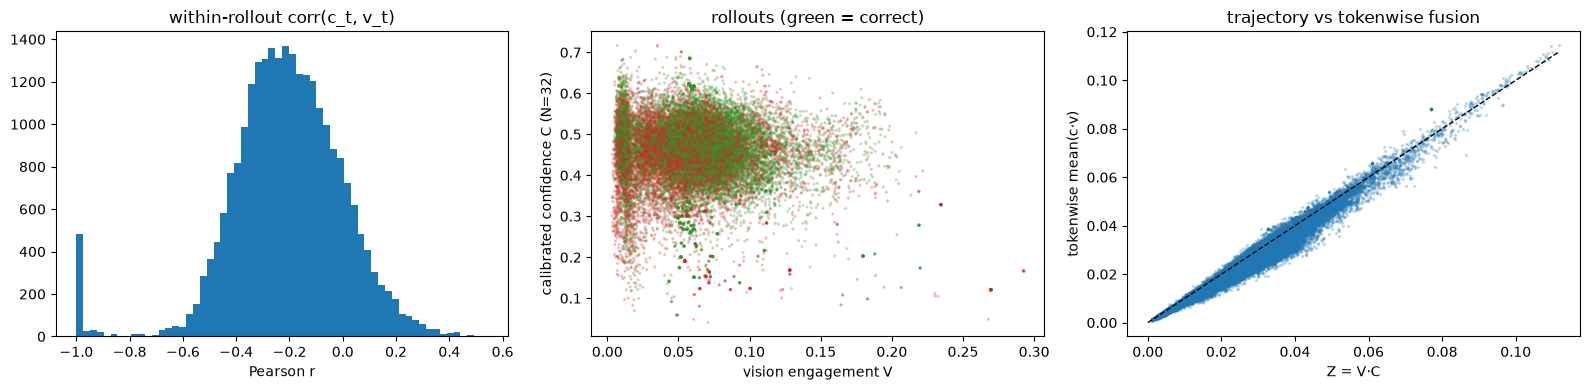

diff                  ci
comparison                              N                             
max tokenwise VisConf − max VisConf     4  -0.0046  [-0.0096, +0.0004]
                                        8  -0.0060  [-0.0130, +0.0008]
                                        16 -0.0109  [-0.0219, -0.0012]
                                        32 -0.0138  [-0.0350, +0.0063]
tokenwise VisConf + RWC − VisConf + RWC 4  -0.0016  [-0.0051, +0.0019]
                                        8   0.0011  [-0.0025, +0.0048]
                                        16  0.0005  [-0.0035, +0.0045]
                                        32 -0.0038  [-0.0100, +0.0025]

In [14]:
# confidence-vision relation (MathVista): within-rollout Pearson correlation between c_t and v_t
r = roll["mathvista"][roll["mathvista"].split == "eval"]
cq = r.groupby("sample_id").cv_corr.median()
print(f"within-rollout corr(c_t, v_t): mean {r.cv_corr.mean():.3f}, median {r.cv_corr.median():.3f}, "
      f"share > 0: {(r.cv_corr > 0).mean():.3f}; per-question median of medians {cq.median():.3f}")
print(f"  correct rollouts {r[r.correct].cv_corr.mean():.3f} vs incorrect {r[~r.correct].cv_corr.mean():.3f}")
print(f"Ztok - Z = Cov_t(c, v): mean {(r.Ztok32 - r.Z32).mean():.5f} (Z mean {r.Z32.mean():.4f})")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(r.cv_corr.dropna(), bins=60); ax[0].set_title("within-rollout corr(c_t, v_t)"); ax[0].set_xlabel("Pearson r")
ax[1].scatter(r.V, r.C32, s=2, alpha=.2, c=r.correct.map({True: "tab:green", False: "tab:red"}))
ax[1].set_xlabel("vision engagement V"); ax[1].set_ylabel("calibrated confidence C (N=32)"); ax[1].set_title("rollouts (green = correct)")
ax[2].scatter(r.Z32, r.Ztok32, s=2, alpha=.2); ax[2].plot([0, r.Z32.max()], [0, r.Z32.max()], "k--", lw=1)
ax[2].set_xlabel("Z = V·C"); ax[2].set_ylabel("tokenwise mean(c·v)"); ax[2].set_title("trajectory vs tokenwise fusion")
plt.tight_layout(); plt.show()
rows = []
for a, b in [("MaxVisConfTok", "MaxVisConf"), ("VisConfTok_RWC", "VisConf_RWC")]:
    for N in [4, 8, 16, 32]:
        mu, lo, hi = boot_diff("mathvista", a, b, N)
        rows.append(dict(comparison=f"{LBL[a]} − {LBL[b]}", N=N, diff=mu, ci=f"[{lo:+.4f}, {hi:+.4f}]"))
display(pd.DataFrame(rows).set_index(["comparison", "N"]).round(4))

Illustrative trajectories (fixed rule, chosen before looking at them): the first four evaluation questions (split
order) whose 32 MathVista rollouts have mixed correctness; for each, the highest-VisConf correct and the
highest-VisConf incorrect rollout. Curves are 25-token moving averages of calibrated confidence c_t (N = 32 pool
calibration) and visual engagement v_t.

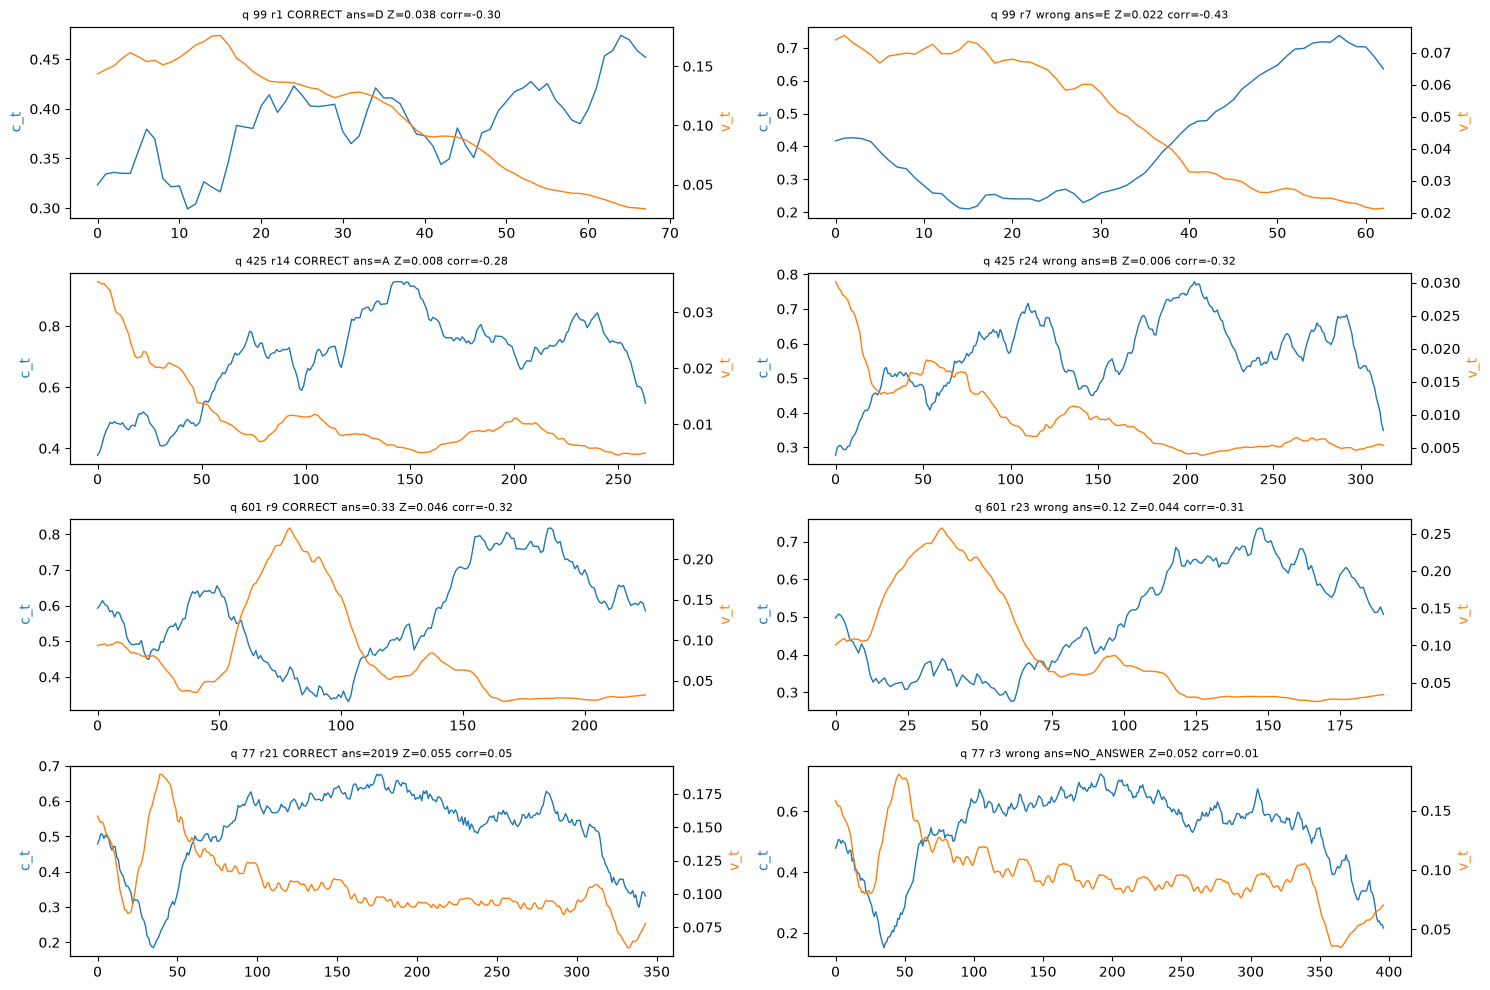

--- q 99 rollout 1 (correct)
Which cat is larger? A. white five B. white three C. white four D. white one E. white two
Let's analyze the image step by step: 1. The image shows a woman, a white cat, and a gray cat in a room. 2. The white cat is jumping onto a chair. 3. The gray cat is on the floor, looking up at the white cat. 4. The white cat is clearly larger than the gray cat. Given this information, the larger cat is the white one. Therefore, the answer is D. white one.
--- q 99 rollout 7 (wrong)
Which cat is larger? A. white five B. white three C. white four D. white one E. white two
To determine which cat is larger, let's analyze the information provided: 1. The question asks about the size of the cats. 2. The cats are described as "white" and "gray." 3. The size of the cats is not specified in the description. Since the size of the cats is not provided, we cannot determine which cat is larger based on the given information. Therefore, the answer is \boxed{E}.


In [15]:
traj = json.load(open(f"{R}/trajectories.json"))
keys = list(traj); fig, ax = plt.subplots(len(keys) // 2, 2, figsize=(15, 2.6 * len(keys) // 2), squeeze=False)
sm = lambda x, w=25: np.convolve(x, np.ones(w) / w, mode="valid") if len(x) > w else np.asarray(x)
for k, a in zip(keys, ax.flat):
    t = traj[k]; a2 = a.twinx()
    a.plot(sm(t["c"]), c="tab:blue", lw=1); a2.plot(sm(t["v"]), c="tab:orange", lw=1)
    a.set_ylabel("c_t", color="tab:blue"); a2.set_ylabel("v_t", color="tab:orange")
    a.set_title(f"q {t['sample_id']} r{t['rollout_id']} {'CORRECT' if t['correct'] else 'wrong'} ans={t['group']} "
                f"Z={t['Z32']:.3f} corr={t['cv_corr']:.2f}", fontsize=8)
plt.tight_layout(); plt.show()
for k in keys[:2]:
    t = traj[k]; print(f"--- q {t['sample_id']} rollout {t['rollout_id']} ({'correct' if t['correct'] else 'wrong'})")
    print(textwrap.shorten(t["question"], 300)); print(textwrap.shorten(t["text"], 700))

## 4. Parallel sampling vs a longer response vs sequential refinement (live, 50 MATH questions)

In [16]:
calls = pd.DataFrame([json.loads(l) for p in sorted(glob.glob(f"{R}/live_calls_*.jsonl")) for l in open(p)])
graded = pd.DataFrame(json.load(open(f"{R}/live_graded.json")))
env = [json.load(open(p)) for p in sorted(glob.glob(f"{R}/live_env_*.json"))]
print({k: env[0][k] for k in ["model", "revision", "dtype", "batch_size", "gpu", "torch", "transformers", "sampling", "caps"]})
assert len(graded) == 50 and set(graded.sample_id) == set(splits["math"]["eval"][:50])
c = calls.set_index(["sample_id", "strategy", "k"])
def agg(parts):
    x = pd.concat([p.reset_index()[["sample_id", "input_tokens", "output_tokens", "seconds", "peak_mem_gb"]] for p in parts])
    g = x.groupby("sample_id")      # per-question totals over all calls of the strategy
    return dict(input_tokens=g.input_tokens.sum().mean(), output_tokens=g.output_tokens.sum().mean(),
                seconds=g.seconds.sum().mean(), peak_mem_gb=x.peak_mem_gb.max())
S = c.xs("single", level=1); P = c.xs("parallel", level=1); Rf = c.xs("refine", level=1); P0 = P.xs(0, level=1)
strat = {
    "single (1 x 3072)": (agg([S]), graded.single_correct.mean(), S.truncated.mean(), S.extracted.isna().mean()),
    "parallel (3 x 1024, SC)": (agg([P]), graded.parallel_correct.mean(), P.truncated.mean(), P.extracted.isna().mean()),
    "refinement (1024 + 2048)": (agg([P0, Rf]), graded.refine_correct.mean(), Rf.truncated.mean(), Rf.extracted.isna().mean()),
    "  initial response only": (agg([P0]), graded.initial_correct.mean(), P0.truncated.mean(), P0.extracted.isna().mean()),
}
rows = []
for k, (a, acc, tr, na) in strat.items():
    rows.append(dict(strategy=k, accuracy=acc, **a, truncation_rate=tr, extraction_failure_rate=na))
lt = pd.DataFrame(rows).set_index("strategy")
display(lt.round(3))
print(f"parallel oracle coverage (any of 3 correct): {graded.parallel_coverage.mean():.3f}")
print(f"refinement: revision prompt input tokens mean {Rf.input_tokens.mean():.0f} vs initial {P0.input_tokens.mean():.0f}")
tr = pd.crosstab(graded.initial_correct.map({True: "initial correct", False: "initial wrong"}),
                 graded.refine_correct.map({True: "revised correct", False: "revised wrong"}))
display(tr)
chg = (graded.initial_answer.fillna("∅") != graded.refine_answer.fillna("∅")).mean()
print(f"revised answer string differs from initial: {chg:.3f}")
n = len(graded); diffs = {}
for a, b in [("parallel_correct", "single_correct"), ("refine_correct", "single_correct"), ("refine_correct", "parallel_correct"),
             ("refine_correct", "initial_correct")]:
    d = (graded[a].astype(float) - graded[b].astype(float)).to_numpy()
    bs = d[np.random.default_rng(6304).integers(0, n, size=(1000, n))].mean(1)
    diffs[f"{a} - {b}"] = f"{d.mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]"
print("paired bootstrap differences (50 questions):", json.dumps(diffs, indent=1))

{'model': 'Qwen/Qwen2.5-3B-Instruct', 'revision': 'aa8e72537993ba99e69dfaafa59ed015b17504d1', 'dtype': 'float16', 'batch_size': 1, 'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'sampling': {'do_sample': True, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'repetition_penalty': 1.0}, 'caps': {'single': 3072, 'parallel': 1024, 'refine': 2048}}


,accuracy,input_tokens,output_tokens,seconds,peak_mem_gb,truncation_rate,extraction_failure_rate
strategy,,,,,,,
single (1 x 3072),0.66,108.38,734.22,36.884,6.084,0.04,0.04
"parallel (3 x 1024, SC)",0.62,325.14,1821.12,90.686,5.935,0.16,0.16
refinement (1024 + 2048),0.64,837.34,1132.54,56.875,6.168,0.00,0.00
initial response only,0.64,108.38,583.48,29.034,5.934,0.10,0.10


parallel oracle coverage (any of 3 correct): 0.700
refinement: revision prompt input tokens mean 729 vs initial 108


refine_correct,revised correct,revised wrong
initial_correct,,
initial correct,31,1
initial wrong,1,17


revised answer string differs from initial: 0.120
paired bootstrap differences (50 questions): {
 "parallel_correct - single_correct": "-0.040 [-0.160, +0.060]",
 "refine_correct - single_correct": "-0.020 [-0.120, +0.080]",
 "refine_correct - parallel_correct": "+0.020 [-0.060, +0.120]",
 "refine_correct - initial_correct": "+0.000 [-0.060, +0.060]"
}


## 5. Adaptive sampling (offline stopping between completed rollouts)

In [17]:
for d in DS:
    g = pd.read_csv(f"{R}/adaptive_grid_{d}.csv"); ch = json.load(open(f"{R}/adaptive_{d}.json"))
    display(Markdown(f"**{NAME[d]}** — dev fixed-32 SC accuracy {ch['dev_fixed32_acc']:.4f}; tolerance −1 pp; "
                     f"selected: {json.dumps(ch['chosen'])}"))
    display(g.round(4))

**MATH (Qwen2.5-3B)** — dev fixed-32 SC accuracy 0.8250; tolerance −1 pp; selected: {"agreement": {"family": "agreement", "tau": 0.625, "gamma": null, "dev_acc": 0.8260000000000001, "dev_cost": 7088.955499999999}, "quality": {"family": "quality", "tau": 0.5, "gamma": 0.0, "dev_acc": 0.8215, "dev_cost": 5479.528499999999}}

,family,tau,gamma,dev_acc,dev_cost,dev_rollouts
0,fixed32,NaN,NaN,0.8250,18322.4000,32.000
1,agreement,0.500,NaN,0.8145,5052.7900,6.648
2,agreement,0.625,NaN,0.8260,7088.9555,9.150
3,agreement,0.750,NaN,0.8260,7717.4530,10.114
4,agreement,0.875,NaN,0.8260,9980.3455,13.648
5,agreement,1.000,NaN,0.8260,10848.2730,15.172
6,quality,0.500,0.00,0.8215,5479.5285,7.152
7,quality,0.500,0.10,0.8220,5663.5700,7.432
8,quality,0.500,0.25,0.8210,6009.0580,7.914
9,quality,0.500,0.50,0.8225,7018.3400,9.326


**MathVista (Qwen2.5-VL-3B)** — dev fixed-32 SC accuracy 0.6425; tolerance −1 pp; selected: {"agreement": {"family": "agreement", "tau": 0.5, "gamma": null, "dev_acc": 0.6365, "dev_cost": 3576.802}, "quality": {"family": "quality", "tau": 0.5, "gamma": 0.0, "dev_acc": 0.64, "dev_cost": 3977.5745}}

,family,tau,gamma,dev_acc,dev_cost,dev_rollouts
0,fixed32,NaN,NaN,0.6425,9217.4850,32.000
1,agreement,0.500,NaN,0.6365,3576.8020,9.404
2,agreement,0.625,NaN,0.6455,5111.4565,13.760
3,agreement,0.750,NaN,0.6440,5556.5745,15.068
4,agreement,0.875,NaN,0.6420,7051.6310,20.136
5,agreement,1.000,NaN,0.6420,7438.0325,21.920
6,quality,0.500,0.00,0.6400,3977.5745,10.662
7,quality,0.500,0.10,0.6400,4238.4435,11.452
8,quality,0.500,0.25,0.6405,4549.4350,12.392
9,quality,0.500,0.50,0.6430,5424.6535,15.024


In [18]:
rows, stopd = [], {}
for d in DS:
    ids = splits[d]["eval"]; ch = json.load(open(f"{R}/adaptive_{d}.json"))
    f32 = pd.read_parquet(f"{R}/adaptive_eval_{d}_fixed32.parquet")
    a32 = f32.groupby("sample_id").sc_correct.mean().reindex(ids).to_numpy()
    for fam in ["agreement", "quality"]:
        r = pd.read_parquet(f"{R}/adaptive_eval_{d}_{fam}.parquet")
        q = r.groupby("sample_id").agg(acc=("sc_correct", "mean"), cost=("cost", "mean"), n=("n", "mean")).reindex(ids)
        dd = q.acc.to_numpy() - a32; bs = dd[BOOT[d]].mean(1)
        m = r.merge(f32, on=["sample_id", "order"], suffixes=("", "_32"))
        early = m[m.n < 32]; wrong_early = early[~early.sc_correct]
        rows.append(dict(dataset=d, policy=f"{fam} (tau={ch['chosen'][fam]['tau']}, gamma={ch['chosen'][fam]['gamma']})",
                         accuracy=q.acc.mean(), diff_vs_fixed32=f"{dd.mean():+.4f} [{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]",
                         mean_tokens=q.cost.mean(), mean_rollouts=q.n.mean(),
                         early_stop_rate=(m.n < 32).mean(), wrong_early_stops=len(wrong_early) / len(m),
                         wrong_early_recoverable_by_32=(wrong_early.sc_correct_32.mean() if len(wrong_early) else np.nan),
                         early_stops_changed_answer=(early.sc_answer != early.sc_answer_32).mean() if len(early) else np.nan))
        stopd[(d, fam)] = r.n.value_counts(normalize=True).sort_index()
    for N in BUD:
        s = sel[d][(sel[d].method == "SC") & (sel[d].split == "eval") & (sel[d].N == N)]
        q = s.groupby("sample_id").agg(acc=("correct", "mean"), cost=("cost", "mean"))
        rows.append(dict(dataset=d, policy=f"fixed N={N} SC", accuracy=q.acc.mean(), mean_tokens=q.cost.mean(), mean_rollouts=N))
ad = pd.DataFrame(rows).set_index(["dataset", "policy"])
display(ad.round(4))
display(Markdown("Stopping-count distribution (share of question × order runs):"))
display(pd.DataFrame(stopd).T.fillna(0).round(4))

accuracy             diff_vs_fixed32  mean_tokens  mean_rollouts  early_stop_rate  wrong_early_stops  wrong_early_recoverable_by_32  early_stops_changed_answer
dataset   policy                                                                                                                                                                                            
math      agreement (tau=0.625, gamma=None)    0.7364  -0.0015 [-0.0050, +0.0015]   10139.9810        11.8240           0.7346             0.0825                         0.0773                      0.0204
          quality (tau=0.5, gamma=0.0)         0.7317  -0.0061 [-0.0121, -0.0007]    7663.0554         9.0075           0.8352             0.1440                         0.1137                      0.0554
          fixed N=1 SC                         0.6435                         NaN     669.7726         1.0000              NaN                NaN                            NaN                         NaN
          fixed N=2 SC                         0.6435                         NaN    1339.8655         2.0000              NaN                NaN                            NaN                         NaN
          fixed N=4 SC                         0.6920                         NaN    2679.6941         4.0000              NaN                NaN                            NaN                         NaN
          fixed N=8 SC                         0.7179                         NaN    5344.1085         8.0000              NaN                NaN                            NaN                         NaN
          fixed N=16 SC                        0.7311                         NaN   10677.7428        16.0000              NaN                NaN                            NaN                         NaN
          fixed N=32 SC                        0.7379                         NaN   21347.0175        32.0000              NaN                NaN                            NaN                         NaN
mathvista agreement (tau=0.5, gamma=None)      0.6240  -0.0056 [-0.0161, +0.0056]    3115.6816         9.2870           0.8308             0.2279                         0.1744                      0.1327
          quality (tau=0.5, gamma=0.0)         0.6270  -0.0026 [-0.0122, +0.0069]    3454.3498        10.3560           0.7992             0.2031                         0.1582                      0.1107
          fixed N=1 SC                         0.5445                         NaN     277.7964         1.0000              NaN                NaN                            NaN                         NaN
          fixed N=2 SC                         0.5445                         NaN     551.2501         2.0000              NaN                NaN                            NaN                         NaN
          fixed N=4 SC                         0.5889                         NaN    1111.5916         4.0000              NaN                NaN                            NaN                         NaN
          fixed N=8 SC                         0.6091                         NaN    2229.9020         8.0000              NaN                NaN                            NaN                         NaN
          fixed N=16 SC                        0.6209                         NaN    4461.8425        16.0000              NaN                NaN                            NaN                         NaN
          fixed N=32 SC                        0.6296                         NaN    8897.7575        32.0000              NaN                NaN                            NaN                         NaN

Stopping-count distribution (share of question × order runs):

n                        4       8       16      32
math      agreement  0.6627  0.0586  0.0132  0.2654
          quality    0.7636  0.0581  0.0135  0.1648
mathvista agreement  0.7348  0.0755  0.0205  0.1693
          quality    0.6732  0.0971  0.0289  0.2008

## 6. Compute allocation and failure cases

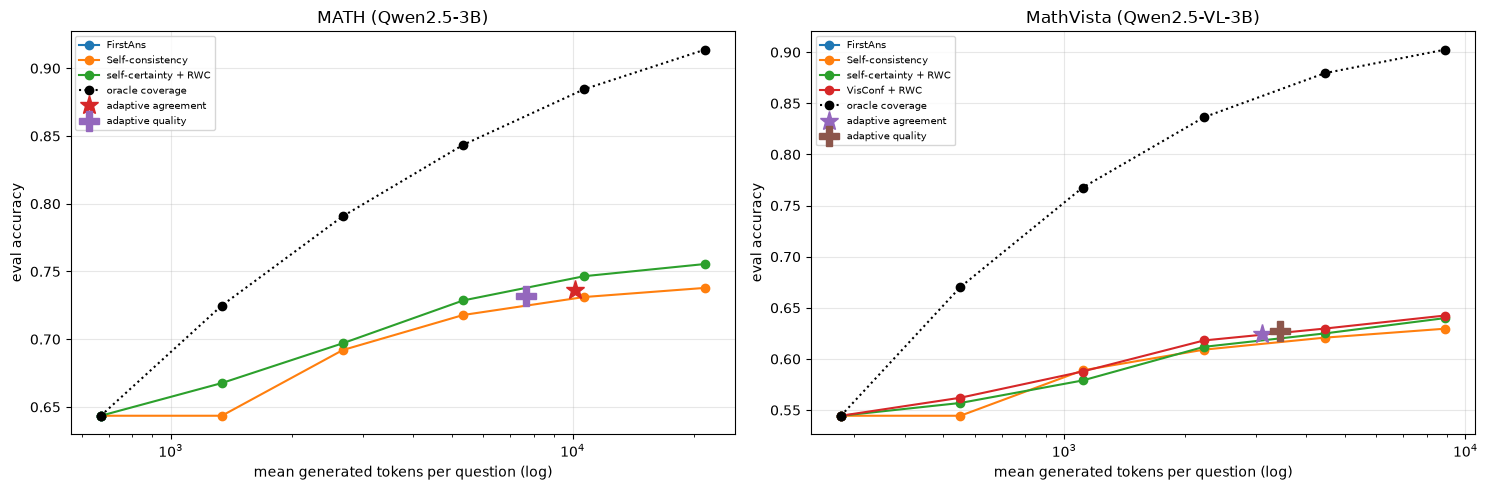

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, d in zip(ax, DS):
    s = sel[d][sel[d].split == "eval"]
    for m in ["FirstAns", "SC", "SC_RWC"] + (["VisConf_RWC"] if d == "mathvista" else []):
        g = s[s.method == m].groupby(["N", "sample_id"]).agg(c=("correct", "mean"), t=("cost", "mean")).groupby("N").mean()
        a.plot(g.t, g.c, "o-", label=LBL[m])
    g = s[s.method == "SC"].groupby(["N", "sample_id"]).agg(c=("coverage", "mean"), t=("cost", "mean")).groupby("N").mean()
    a.plot(g.t, g.c, "k:o", label="oracle coverage")
    r = ad.loc[d]
    for fam, mk in [("agreement", "*"), ("quality", "P")]:
        row = r[r.index.str.startswith(fam)].iloc[0]
        a.plot(row.mean_tokens, row.accuracy, mk, ms=14, label=f"adaptive {fam}")
    a.set_xscale("log"); a.set_xlabel("mean generated tokens per question (log)"); a.set_ylabel("eval accuracy")
    a.set_title(NAME[d]); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [20]:
# do extra samples add new alternatives or repeat existing answers?  (order-averaged, eval)
rows = []
for d in DS:
    s = sel[d][(sel[d].method == "SC") & (sel[d].split == "eval")].set_index(["sample_id", "order", "N"]).sort_index()
    for a, b in zip(BUD[:-1], BUD[1:]):
        x, y = s.xs(a, level="N"), s.xs(b, level="N")
        rows.append(dict(dataset=d, step=f"{a}->{b}", new_groups_per_added_sample=((y.n_groups - x.n_groups) / (b - a)).mean(),
                         coverage_gain=(y.coverage.astype(float) - x.coverage.astype(float)).mean(),
                         sc_acc_gain=(y.correct.astype(float) - x.correct.astype(float)).mean(),
                         sc_answer_changed=(y.sel_answer != x.sel_answer).mean()))
display(pd.DataFrame(rows).set_index(["dataset", "step"]).round(4))

new_groups_per_added_sample  coverage_gain  sc_acc_gain  sc_answer_changed
dataset   step                                                                              
math      1->2                         0.3709         0.0814       0.0000             0.0000
          2->4                         0.2784         0.0659       0.0485             0.1195
          4->8                         0.2032         0.0528       0.0259             0.1234
          8->16                        0.1579         0.0410       0.0132             0.0982
          16->32                       0.1188         0.0292       0.0068             0.0815
mathvista 1->2                         0.4259         0.1259       0.0000             0.0000
          2->4                         0.2589         0.0972       0.0444             0.1626
          4->8                         0.1549         0.0688       0.0202             0.1440
          8->16                        0.0907         0.0431       0.0118             0.1148
          16->32                       0.0530         0.0230       0.0088             0.0915

**MATH (Qwen2.5-3B)**

,mean_rollouts,acc,runs
bin,,,
"(-0.01, 0.0]",18.516,0.000,690
"(0.0, 0.25]",19.434,0.150,1420
"(0.25, 0.5]",12.374,0.724,780
"(0.5, 0.75]",5.697,0.962,740
"(0.75, 0.99]",4.194,0.997,1750
"(0.99, 1.0]",4.000,1.000,2620


math SC correctness by leading-answer share at n=8: {Interval(0.0, 0.5, closed='right'): 0.293, Interval(0.5, 0.625, closed='right'): 0.648, Interval(0.625, 0.75, closed='right'): 0.786, Interval(0.75, 0.875, closed='right'): 0.886, Interval(0.875, 1.0, closed='right'): 0.977}


**MathVista (Qwen2.5-VL-3B)**

,mean_rollouts,acc,runs
bin,,,
"(-0.01, 0.0]",22.328,0.000,780
"(0.0, 0.25]",17.195,0.071,1540
"(0.25, 0.5]",12.759,0.510,1370
"(0.5, 0.75]",6.718,0.922,1310
"(0.75, 0.99]",4.310,1.000,2170
"(0.99, 1.0]",4.000,1.000,830


mathvista SC correctness by leading-answer share at n=8: {Interval(0.0, 0.5, closed='right'): 0.308, Interval(0.5, 0.625, closed='right'): 0.527, Interval(0.625, 0.75, closed='right'): 0.659, Interval(0.75, 0.875, closed='right'): 0.771, Interval(0.875, 1.0, closed='right'): 0.908}


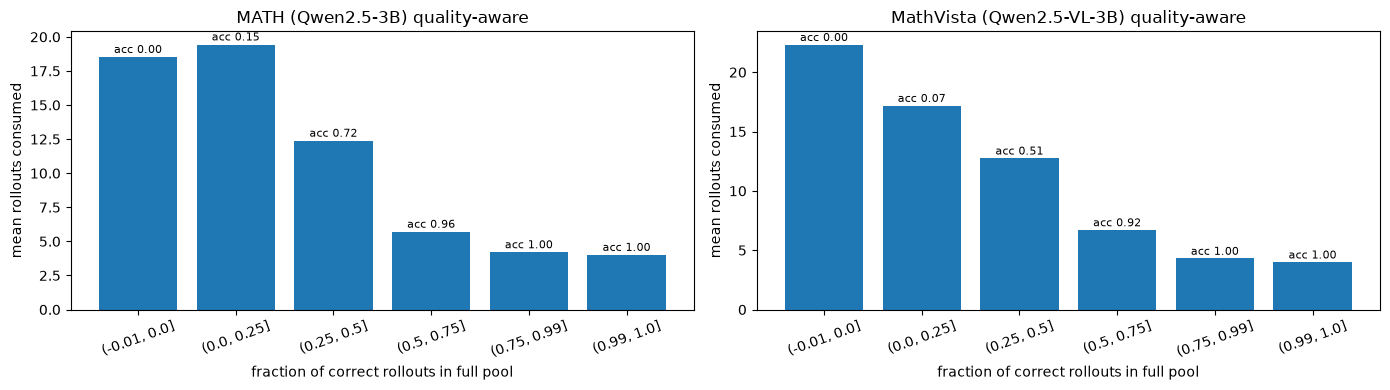

In [21]:
# stopping behaviour vs retrospective fraction of correct candidates in the full pool (analysis only)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, d in zip(ax, DS):
    pc = roll[d].groupby("sample_id").correct.mean()
    r = pd.read_parquet(f"{R}/adaptive_eval_{d}_quality.parquet")
    r["pool_frac_correct"] = r.sample_id.map(pc); r["bin"] = pd.cut(r.pool_frac_correct, [-.01, 0, .25, .5, .75, .99, 1])
    t = r.groupby("bin", observed=True).agg(mean_rollouts=("n", "mean"), acc=("sc_correct", "mean"), runs=("n", "size"))
    a.bar(range(len(t)), t.mean_rollouts); a.set_xticks(range(len(t)), [str(i) for i in t.index], rotation=20)
    a.set_xlabel("fraction of correct rollouts in full pool"); a.set_ylabel("mean rollouts consumed"); a.set_title(f"{NAME[d]} quality-aware")
    for i, (n_, acc) in enumerate(zip(t.mean_rollouts, t.acc)): a.text(i, n_ + .3, f"acc {acc:.2f}", ha="center", fontsize=8)
    display(Markdown(f"**{NAME[d]}**")); display(t.round(3))
    st = pd.read_parquet(f"{R}/adaptive_state_{d}.parquet")
    st = st[st.sample_id.isin(splits[d]["eval"])]
    print(d, "SC correctness by leading-answer share at n=8:",
          st[st.n == 8].groupby(pd.cut(st[st.n == 8].lead_frac, [0, .5, .625, .75, .875, 1])).sc_correct.mean().round(3).to_dict())
plt.tight_layout(); plt.show()

### Representative cases (fixed selection rules)

* **Selection disagreement**: the first three evaluation questions (split order) where, at N = 32 in order 0,
  self-consistency and the quality-aware RWC rule (self-certainty for MATH, VisConf for MathVista) return different
  answers.
* **Revision**: the first two live questions (split order) with a wrong→correct and a correct→wrong transition.
* **Premature stopping**: the first three (question, order) evaluation runs, in split order then order index, where
  the selected quality-aware policy stops early with a wrong answer that fixed-32 self-consistency gets right.

In [22]:
texts = {d: pd.read_parquet(f"{R}/texts_{d}.parquet").set_index(["sample_id", "rollout_id"]) for d in DS}
REPS = {d: json.load(open(f"{R}/groups_{d}.json"))["reps"] for d in DS}
rep = lambda d, q, g: REPS[d][q].get(g, g)
for d, m in [("math", "SC_RWC"), ("mathvista", "VisConf_RWC")]:
    s = sel[d][(sel[d].split == "eval") & (sel[d].N == 32) & (sel[d].order == 0)].set_index(["sample_id", "method"])
    n = 0
    for q in splits[d]["eval"]:
        a, b = s.loc[(q, "SC")], s.loc[(q, m)]
        if a.sel_answer == b.sel_answer: continue
        rq = roll[d][roll[d].sample_id == q]
        votes = rq.groupby("group").agg(votes=("rollout_id", "size"), correct=("correct", "first"),
                                        mean_K=("K", "mean")).sort_values("votes", ascending=False)
        print(f"=== {d} q={q} gold={rq.gold_answer.iloc[0]!r}")
        print("   ", textwrap.shorten(texts[d].loc[(q, 0)].question_text, 220))
        print(f"    SC -> {rep(d, q, a.sel_answer)!r} ({'correct' if a.correct else 'wrong'}) | {LBL[m]} -> "
              f"{rep(d, q, b.sel_answer)!r} ({'correct' if b.correct else 'wrong'})")
        votes.index = [rep(d, q, g) for g in votes.index]
        print(votes.head(5).to_string())
        n += 1
        if n == 3: break

=== math q=test:2460 gold='154'
    At a competition with $N$ players, the number of players given elite status is equal to $2^{1+\lfloor \log_{2} (N-1) \rfloor}-N$. Suppose that $19$ players are given elite status. What is the sum of the two [...]
    SC -> '58' (wrong) | self-certainty + RWC -> '154' (correct)
           votes  correct     mean_K
154           11     True  27.384331
58            11    False  27.269869
NO_ANSWER      3    False  26.165514
45             1    False  27.446264
98             1    False  26.029659
=== math q=test:2892 gold='-71'
    There is a unique polynomial $P(x)$ of degree $8$ with rational coefficients and leading coefficient $1,$ which has the number \[\sqrt{2} + \sqrt{3} + \sqrt{5}\]as a root. Compute $P(1).$
    SC -> '1' (wrong) | self-certainty + RWC -> '0' (wrong)
           votes  correct     mean_K
0              4    False  28.020945
1              4    False  27.433550
23             2    False  28.503365
NO_ANSWER      1    False  25.44

In [23]:
g = graded.set_index("sample_id")
for kind, (a, b) in {"wrong->correct": (False, True), "correct->wrong": (True, False)}.items():
    qs = [q for q in splits["math"]["eval"][:50] if g.loc[q, "initial_correct"] == a and g.loc[q, "refine_correct"] == b][:2]
    print(f"===== {kind}: {len(qs)} shown")
    for q in qs:
        ini, rev = c.loc[(q, "parallel", 0)], c.loc[(q, "refine", 0)]
        print(f"--- {q} gold={g.loc[q, 'gold']!r} initial={ini.extracted!r} revised={rev.extracted!r}")
        print("  initial (tail):", textwrap.shorten(ini.response[-600:], 400))
        print("  revision (head):", textwrap.shorten(rev.response[:700], 500))

===== wrong->correct: 1 shown
--- test:2340 gold='6' initial=nan revised='6'
  initial (tail): expression: \[ \frac{x^3 + 2y^3 + 4z^3}{xyz} = \frac{k + 2 \cdot \frac{k}{2} + 4 \cdot \frac{k}{4}}{\sqrt[3]{k} \cdot \sqrt[3]{\frac{k}{2}} \cdot \sqrt[3]{\frac{k}{4}}} \] Simplify the numerator: \[ k + k + k = 3k \] Simplify the denominator: \[ \sqrt[3]{k} \cdot \sqrt[3]{\frac{k}{2}} \cdot \sqrt[3]{\frac{k}{4}} = \sqrt[3]{k \cdot \frac{k}{2} \cdot \frac{k}{4}} = \sqrt[3]{\frac{k^3}{8}} = [...]
  revision (head): The solution provided is correct, but let's ensure all steps are clearly laid out for clarity. Given the expression: \[ \frac{x^3 + 2y^3 + 4z^3}{xyz} \] We apply the AM-GM Inequality to the terms \(x^3\), \(2y^3\), and \(4z^3\): \[ \frac{x^3 + 2y^3 + 4z^3}{3} \geq \sqrt[3]{x^3 \cdot 2y^3 \cdot 4z^3} \] Simplify the right-hand side: \[ \sqrt[3]{x^3 \cdot 2y^3 \cdot 4z^3} = \sqrt[3]{8 (xyz)^3} = \sqrt[3]{8} \cdot (xyz) = 2 \sqrt[3]{2} \cdot (xyz) \] Thus: \[ \frac{x^3 + 2y^3 + 4z^3}{3}

In [24]:
for d in DS:
    r = pd.read_parquet(f"{R}/adaptive_eval_{d}_quality.parquet").merge(
        pd.read_parquet(f"{R}/adaptive_eval_{d}_fixed32.parquet"), on=["sample_id", "order"], suffixes=("", "_32"))
    r = r[(r.n < 32) & ~r.sc_correct & r.sc_correct_32]
    pos = {q: i for i, q in enumerate(splits[d]["eval"])}
    r = r.assign(p=r.sample_id.map(pos)).sort_values(["p", "order"]).head(3)
    st = pd.read_parquet(f"{R}/adaptive_state_{d}.parquet").set_index(["sample_id", "order", "n"])
    for _, x in r.iterrows():
        s = st.loc[(x.sample_id, x.order, x.n)]
        print(f"{d} q={x.sample_id} order={x.order}: stopped at n={x.n} with {rep(d, x.sample_id, x.sc_answer)!r} (lead share {s.lead_frac:.2f}, "
              f"RWC margin {s.rwc_margin:.2f}); fixed-32 answer {rep(d, x.sample_id, x.sc_answer_32)!r} is correct; "
              f"full-pool correct share {roll[d][roll[d].sample_id == x.sample_id].correct.mean():.2f}")

math q=test:3504 order=7: stopped at n=4 with '120' (lead share 0.50, RWC margin 0.67); fixed-32 answer '216' is correct; full-pool correct share 0.41
math q=test:2460 order=7: stopped at n=4 with '58' (lead share 0.75, RWC margin 0.33); fixed-32 answer '154' is correct; full-pool correct share 0.34
math q=test:534 order=2: stopped at n=4 with '48' (lead share 0.50, RWC margin 0.00); fixed-32 answer '56' is correct; full-pool correct share 0.72
mathvista q=601 order=1: stopped at n=4 with '0.47' (lead share 0.75, RWC margin 1.00); fixed-32 answer '0.33' is correct; full-pool correct share 0.38
mathvista q=601 order=8: stopped at n=4 with '0.47' (lead share 0.50, RWC margin 0.00); fixed-32 answer '0.33' is correct; full-pool correct share 0.38
mathvista q=358 order=4: stopped at n=4 with 'D' (lead share 0.50, RWC margin 0.33); fixed-32 answer 'A' is correct; full-pool correct share 0.44


## 7. Notes, deviations and cost caveats

* Token costs are generated-token counts of the supplied rollouts (offline proxy); they exclude prefill, attention
  collection and scoring. Live costs (Section 4) are actual input/output tokens and wall-clock time on a T4 (FP16,
  batch 1, HF `generate`), excluding model loading.
* The live runs are a new FP16 comparison on Kaggle T4 GPUs (the two GPUs of the job each served 25 questions; all
  strategies of one question ran on the same GPU), not a reproduction of the supplied samples.
* Gold answers are used only for grading and for the retrospective analyses that are labelled as such; selection,
  stopping, VisConf calibration and ranks use only the currently revealed candidates.
* The report text (interpretation of these results) is to be written separately, per the course AI-usage policy.